In [18]:

# ============================================================
# CELL 1: ENVIRONMENT SETUP AND CONFIGURATION
# Project: Arecanut Ripeness Classification
# Model: MobileNetV2
# ============================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights


# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# 2. DEVICE CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 3. PROJECT DIRECTORIES
# ------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent

print("\nNotebook directory:", NOTEBOOK_DIR)
print("Project directory:", PROJECT_DIR)


# ------------------------------------------------------------
# 4. AUTOMATICALLY LOCATE PROCESSED DATASET
# ------------------------------------------------------------

possible_dataset_paths = [
    PROJECT_DIR / "dataset" / "processed_dataset",
    NOTEBOOK_DIR / "dataset" / "processed_dataset",
]

DATASET_DIR = next(
    (path for path in possible_dataset_paths if path.exists()),
    None
)

# Search within the project if the standard locations fail.
if DATASET_DIR is None:
    matches = list(PROJECT_DIR.rglob("processed_dataset"))

    matches = [
        path for path in matches
        if path.is_dir()
    ]

    if len(matches) == 1:
        DATASET_DIR = matches[0]

    elif len(matches) > 1:
        raise RuntimeError(
            "Multiple processed_dataset folders found:\n"
            + "\n".join(str(path) for path in matches)
            + "\nPlease select the correct dataset directory."
        )

assert DATASET_DIR is not None, (
    "Could not locate processed_dataset. "
    "Please check where the preprocessing notebook saved it."
)

print("\nProcessed dataset found:", DATASET_DIR)


# ------------------------------------------------------------
# 5. AUTOMATICALLY LOCATE NORMALIZATION STATISTICS
# ------------------------------------------------------------

possible_stats_paths = [
    NOTEBOOK_DIR / "research-notes" / "preprocessing"
    / "normalization_stats.json",

    PROJECT_DIR / "research-notes" / "preprocessing"
    / "normalization_stats.json",
]

STATS_PATH = next(
    (path for path in possible_stats_paths if path.exists()),
    None
)

if STATS_PATH is None:
    matches = list(PROJECT_DIR.rglob("normalization_stats.json"))

    if len(matches) == 1:
        STATS_PATH = matches[0]

    elif len(matches) > 1:
        raise RuntimeError(
            "Multiple normalization files found:\n"
            + "\n".join(str(path) for path in matches)
        )

assert STATS_PATH is not None, (
    "Could not locate normalization_stats.json."
)

PREPROCESSING_DIR = STATS_PATH.parent

print("Normalization statistics found:", STATS_PATH)


# ------------------------------------------------------------
# 6. LOAD NORMALIZATION STATISTICS
# ------------------------------------------------------------

with open(STATS_PATH, "r", encoding="utf-8") as file:
    NORMALIZATION_STATS = json.load(file)

print("\nNormalization statistics loaded successfully!")
print(json.dumps(NORMALIZATION_STATS, indent=4))


# ------------------------------------------------------------
# 7. MODEL OUTPUT DIRECTORY
# ------------------------------------------------------------

MODEL_DIR = PROJECT_DIR / "models" / "mobilenetv2"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("\nModel output directory:", MODEL_DIR)


# ------------------------------------------------------------
# 8. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 16

NUM_CLASSES = 2
NUM_EPOCHS_HEAD = 10
NUM_EPOCHS_FINETUNE = 40

TOTAL_MAX_EPOCHS = NUM_EPOCHS_HEAD + NUM_EPOCHS_FINETUNE

print(f"Maximum total epochs: {TOTAL_MAX_EPOCHS}")

LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_FINETUNE = 1e-4

WEIGHT_DECAY = 1e-4

COLOR_SPACES = ["RGB", "HSV", "YCgCr"]
CLASS_NAMES = ["Ripe", "Unripe"]


# ------------------------------------------------------------
# 9. VERIFY DATASET STRUCTURE
# ------------------------------------------------------------

print("\nDATASET VERIFICATION")
print("=" * 65)

for color_space in COLOR_SPACES:

    print(f"\n{color_space}")

    for split in ["train", "validation", "test"]:

        split_path = DATASET_DIR / color_space / split

        assert split_path.exists(), (
            f"Missing directory: {split_path}"
        )

        for class_name in CLASS_NAMES:

            class_path = split_path / class_name

            assert class_path.exists(), (
                f"Missing directory: {class_path}"
            )

            image_count = len(list(class_path.glob("*.png")))

            print(
                f"{split:12s} | "
                f"{class_name:8s} | "
                f"{image_count:4d} images"
            )


# ------------------------------------------------------------
# 10. FINAL CONFIGURATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SETUP COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Dataset:", DATASET_DIR)
print("Statistics:", STATS_PATH)
print("Model directory:", MODEL_DIR)
print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)
print("Color spaces:", COLOR_SPACES)


PyTorch version: 2.15.0+cu132
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Notebook directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks
Project directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter

Processed dataset found: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset
Normalization statistics found: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\research-notes\preprocessing\normalization_stats.json

Normalization statistics loaded successfully!
{
    "RGB": {
        "mean": [
            0.3409183707365453,
            0.31965236125256286,
            0.246347647622037
        ],
        "std": [
            0.3073407603064623,
            0.2990722908867604,
            0.2818262994987366
        ]
    },
    "HSV": {
        "mean": [
            0.1791005163545884,
 

In [6]:

# ============================================================
# CELL 2: VERIFY IMAGE CHANNEL ORDERING
# ============================================================

from PIL import Image
import cv2
import numpy as np

for color_space in COLOR_SPACES:

    image_path = (
        DATASET_DIR
        / color_space
        / "train"
        / "Ripe"
    )

    sample_file = next(image_path.glob("*.png"))

    # Load using PIL (ImageFolder's image-reading backend)
    pil_image = np.array(
        Image.open(sample_file).convert("RGB")
    )

    # Load using OpenCV and convert BGR -> RGB
    cv_image = cv2.imread(str(sample_file))
    cv_image = cv2.cvtColor(
        cv_image,
        cv2.COLOR_BGR2RGB
    )

    # Compare both representations
    identical = np.array_equal(pil_image, cv_image)

    print(f"\nColor space: {color_space}")
    print("Sample:", sample_file.name)
    print("Image shape:", pil_image.shape)
    print("PIL and OpenCV arrays identical:", identical)
    print("Channel means:", np.round(
        pil_image.astype(np.float32).mean(axis=(0, 1)) / 255,
        4
    ))

    assert identical, (
        f"Channel-order mismatch detected in {color_space}"
    )

print("\nAll image-reading checks passed!")



Color space: RGB
Sample: 1.png
Image shape: (224, 224, 3)
PIL and OpenCV arrays identical: True
Channel means: [0.3591 0.308  0.2701]

Color space: HSV
Sample: 1.png
Image shape: (224, 224, 3)
PIL and OpenCV arrays identical: True
Channel means: [0.2772 0.2791 0.379 ]

Color space: YCgCr
Sample: 1.png
Image shape: (224, 224, 3)
PIL and OpenCV arrays identical: True
Channel means: [0.3114 0.4972 0.5451]

All image-reading checks passed!


In [11]:

# ============================================================
# CELL 3: CORRECTED PYTORCH DATA LOADERS
# ============================================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader


def get_transforms(color_space):

    mean = NORMALIZATION_STATS[color_space]["mean"]
    std = NORMALIZATION_STATS[color_space]["std"]

    assert len(mean) == 3 and len(std) == 3
    assert all(value > 0 for value in std)

    # Fill rotation borders using channel means.
    # This makes the normalized fill approximately zero.
    rotation_fill = tuple(
        int(round(value * 255))
        for value in mean
    )

    train_transform = transforms.Compose([

        transforms.RandomHorizontalFlip(p=0.5),

        transforms.RandomRotation(
            degrees=10,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=rotation_fill
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=mean,
            std=std
        )
    ])

    evaluation_transform = transforms.Compose([

        transforms.ToTensor(),

        transforms.Normalize(
            mean=mean,
            std=std
        )
    ])

    return train_transform, evaluation_transform


# ------------------------------------------------------------
# CREATE DATASETS AND LOADERS
# ------------------------------------------------------------

dataloaders = {}
datasets_dict = {}

for color_space in COLOR_SPACES:

    print(f"\nCreating loaders for {color_space}...")

    train_transform, evaluation_transform = get_transforms(
        color_space
    )

    train_dataset = datasets.ImageFolder(
        DATASET_DIR / color_space / "train",
        transform=train_transform
    )

    val_dataset = datasets.ImageFolder(
        DATASET_DIR / color_space / "validation",
        transform=evaluation_transform
    )

    test_dataset = datasets.ImageFolder(
        DATASET_DIR / color_space / "test",
        transform=evaluation_transform
    )

    assert train_dataset.class_to_idx == {
        "Ripe": 0,
        "Unripe": 1
    }

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    dataloaders[color_space] = {
        "train": train_loader,
        "validation": val_loader,
        "test": test_loader
    }

    datasets_dict[color_space] = {
        "train": train_dataset,
        "validation": val_dataset,
        "test": test_dataset
    }

    print("Training:", len(train_dataset))
    print("Validation:", len(val_dataset))
    print("Testing:", len(test_dataset))
    print(
    "Rotation fill:",
    tuple(
        int(round(value * 255))
        for value in NORMALIZATION_STATS[color_space]["mean"]
    )
)


print("\nCorrected data loaders created successfully!")



Creating loaders for RGB...
Training: 558
Validation: 69
Testing: 70
Rotation fill: (87, 82, 63)

Creating loaders for HSV...
Training: 558
Validation: 69
Testing: 70
Rotation fill: (46, 74, 90)

Creating loaders for YCgCr...
Training: 558
Validation: 69
Testing: 70
Rotation fill: (78, 131, 140)

Corrected data loaders created successfully!


In [12]:

# ============================================================
# CELL 4: VERIFY DATA LOADER OUTPUT
# ============================================================

for color_space in COLOR_SPACES:

    images, labels = next(
        iter(dataloaders[color_space]["train"])
    )

    print(f"\nColor space: {color_space}")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image tensor dtype:", images.dtype)
    print("Label tensor dtype:", labels.dtype)
    print("Image device:", images.device)

    print("Minimum normalized value:", images.min().item())
    print("Maximum normalized value:", images.max().item())

    assert images.shape[1:] == (3, 224, 224)
    assert labels.ndim == 1
    assert images.dtype == torch.float32
    assert labels.dtype == torch.int64

print("\nData loader verification completed!")



Color space: RGB
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Image device: cpu
Minimum normalized value: -1.1092519760131836
Maximum normalized value: 2.674173355102539

Color space: HSV
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Image device: cpu
Minimum normalized value: -1.1328010559082031
Maximum normalized value: 3.464446544647217

Color space: YCgCr
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Image device: cpu
Minimum normalized value: -3.252589225769043
Maximum normalized value: 7.878327369689941

Data loader verification completed!


In [9]:

# ============================================================
# CELL 5: VERIFY AND RECALCULATE TRAINING-ONLY STATISTICS
# ============================================================

from PIL import Image
import numpy as np

training_stats = {}

for color_space in COLOR_SPACES:

    train_dir = DATASET_DIR / color_space / "train"

    # Accumulate channel statistics using float64
    channel_sum = np.zeros(3, dtype=np.float64)
    channel_squared_sum = np.zeros(3, dtype=np.float64)
    total_pixels = 0

    raw_min = np.full(3, np.inf)
    raw_max = np.full(3, -np.inf)

    for class_name in CLASS_NAMES:

        class_dir = train_dir / class_name

        for image_path in class_dir.glob("*.png"):

            image = np.asarray(
                Image.open(image_path).convert("RGB"),
                dtype=np.float64
            ) / 255.0

            pixels = image.reshape(-1, 3)

            channel_sum += pixels.sum(axis=0)
            channel_squared_sum += (pixels ** 2).sum(axis=0)

            raw_min = np.minimum(raw_min, pixels.min(axis=0))
            raw_max = np.maximum(raw_max, pixels.max(axis=0))

            total_pixels += pixels.shape[0]

    mean = channel_sum / total_pixels

    variance = (
        channel_squared_sum / total_pixels
    ) - (mean ** 2)

    std = np.sqrt(np.maximum(variance, 0))

    training_stats[color_space] = {
        "mean": mean.tolist(),
        "std": std.tolist()
    }

    print(f"\n{'=' * 55}")
    print(f"COLOR SPACE: {color_space}")
    print(f"{'=' * 55}")

    print("Training pixels:", total_pixels)
    print("Raw channel minimum:", np.round(raw_min, 5))
    print("Raw channel maximum:", np.round(raw_max, 5))
    print("Training mean:", np.round(mean, 6))
    print("Training std:", np.round(std, 6))


print("\nTraining-only normalization statistics calculated.")



COLOR SPACE: RGB
Training pixels: 27998208
Raw channel minimum: [0. 0. 0.]
Raw channel maximum: [1. 1. 1.]
Training mean: [0.340918 0.319652 0.246348]
Training std: [0.307341 0.299072 0.281826]

COLOR SPACE: HSV
Training pixels: 27998208
Raw channel minimum: [0. 0. 0.]
Raw channel maximum: [1. 1. 1.]
Training mean: [0.179101 0.292135 0.353566]
Training std: [0.235818 0.284326 0.312116]

COLOR SPACE: YCgCr
Training pixels: 27998208
Raw channel minimum: [0.      0.36078 0.24706]
Raw channel maximum: [1.      0.78431 1.     ]
Training mean: [0.306717 0.513568 0.547877]
Training std: [0.291699 0.026402 0.069578]

Training-only normalization statistics calculated.


In [13]:

# ============================================================
# CELL 6: BUILD PRETRAINED MOBILENETV2
# ============================================================

def build_mobilenetv2(freeze_backbone=True):

    # Load ImageNet-pretrained MobileNetV2
    model = mobilenet_v2(
        weights=MobileNet_V2_Weights.IMAGENET1K_V2
    )

    # Freeze pretrained feature extractor
    if freeze_backbone:

        for param in model.features.parameters():
            param.requires_grad = False

    # Get the input features of the original classifier
    in_features = model.classifier[1].in_features

    # Replace final classification layer
    model.classifier[1] = nn.Linear(
        in_features,
        NUM_CLASSES
    )

    # Move model to GPU/CPU
    model = model.to(DEVICE)

    return model


# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

model = build_mobilenetv2(freeze_backbone=True)


# ------------------------------------------------------------
# INSPECT MODEL
# ------------------------------------------------------------

print(model)

print("\nModel device:", next(model.parameters()).device)

print(
    "\nFinal classification layer:",
    model.classifier[1]
)


# ------------------------------------------------------------
# CHECK TRAINABLE PARAMETERS
# ------------------------------------------------------------

total_params = sum(
    param.numel()
    for param in model.parameters()
)

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print(
    "Frozen parameters:",
    f"{total_params - trainable_params:,}"
)


# ------------------------------------------------------------
# VERIFY OUTPUT SHAPE
# ------------------------------------------------------------

dummy_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE
).to(DEVICE)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("\nDummy input shape:", dummy_input.shape)
print("Model output shape:", output.shape)

assert output.shape == (2, NUM_CLASSES)

print("\nMobileNetV2 architecture verified successfully!")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\gsama/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 39.9MB/s]


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [14]:

# ============================================================
# CELL 7: TRAINING CONFIGURATION AND UTILITIES
# ============================================================

import copy
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. LOSS FUNCTION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# 2. OPTIMIZER CONFIGURATION
# ------------------------------------------------------------

def get_optimizer(model, phase):

    if phase == 1:

        parameters = model.classifier.parameters()
        learning_rate = LEARNING_RATE_HEAD

    elif phase == 2:

        parameters = filter(
            lambda p: p.requires_grad,
            model.parameters()
        )
        learning_rate = LEARNING_RATE_FINETUNE

    else:
        raise ValueError("Phase must be 1 or 2.")

    optimizer = optim.AdamW(
        parameters,
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    return optimizer


# ------------------------------------------------------------
# 3. LEARNING RATE SCHEDULER
# ------------------------------------------------------------

def get_scheduler(optimizer):

    return optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )


# ------------------------------------------------------------
# 4. EARLY STOPPING CONFIGURATION
# ------------------------------------------------------------

EARLY_STOPPING_PATIENCE = 5


# ------------------------------------------------------------
# 5. FINE-TUNING CONFIGURATION
# ------------------------------------------------------------

def unfreeze_last_blocks(model, number_of_blocks=3):

    # Freeze all feature extractor parameters first
    for param in model.features.parameters():
        param.requires_grad = False

    # Unfreeze selected final feature blocks
    for block in list(model.features.children())[-number_of_blocks:]:

        for param in block.parameters():
            param.requires_grad = True

    # Keep BatchNorm running statistics fixed
    for module in model.modules():

        if isinstance(module, nn.BatchNorm2d):
            module.eval()


print("Training utilities configured successfully!")
print("Loss function:", criterion)
print("Optimizer: AdamW")
print("Scheduler: ReduceLROnPlateau")
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Fine-tuning: Last 3 feature blocks")


Training utilities configured successfully!
Loss function: CrossEntropyLoss()
Optimizer: AdamW
Scheduler: ReduceLROnPlateau
Early stopping patience: 5
Fine-tuning: Last 3 feature blocks


In [15]:

# ============================================================
# CELL 8: TRAINING AND VALIDATION FUNCTIONS
# ============================================================

def set_training_mode(model):
    """
    Enable training mode while keeping BatchNorm statistics fixed.
    """

    model.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()


def train_one_epoch(model, loader, optimizer):

    set_training_mode(model)

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ------------------------------------------------------------
# VALIDATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ------------------------------------------------------------
# PHASE TRAINING FUNCTION
# ------------------------------------------------------------

def train_phase(
    model,
    train_loader,
    val_loader,
    phase,
    epochs,
    color_space
):

    optimizer = get_optimizer(model, phase)
    scheduler = get_scheduler(optimizer)

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    patience_counter = 0
    history = []

    print(f"\nStarting Phase {phase}")
    print("=" * 65)

    for epoch in range(epochs):

        start_time = time.time()

        train_loss, train_acc, train_f1 = train_one_epoch(
            model,
            train_loader,
            optimizer
        )

        val_loss, val_acc, val_f1 = evaluate_model(
            model,
            val_loader
        )

        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "learning_rate": current_lr
        })

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch + 1:02d}/{epochs:02d}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Macro F1: {val_f1:.4f} | "
            f"LR: {current_lr:.7f} | "
            f"Time: {elapsed:.1f}s"
        )

        # Save best model based on validation loss
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

            patience_counter = 0

        else:

            patience_counter += 1

        # Early stopping
        if patience_counter >= EARLY_STOPPING_PATIENCE:

            print("\nEarly stopping triggered.")
            break

    # Restore best validation checkpoint
    model.load_state_dict(best_state)

    # Save phase checkpoint
    checkpoint_path = (
        MODEL_DIR /
        f"mobilenetv2_{color_space}_phase{phase}.pth"
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "color_space": color_space,
        "phase": phase,
        "best_val_loss": best_val_loss,
        "history": history,
        "class_to_idx": CLASS_NAMES
    }, checkpoint_path)

    print("\nBest validation loss:", round(best_val_loss, 4))
    print("Checkpoint saved:", checkpoint_path)

    return model, pd.DataFrame(history)
    

print("Training and validation functions defined successfully!")


Training and validation functions defined successfully!


In [16]:

# ============================================================
# CELL 9: MOBILENETV2 RGB - PHASE 1
# ============================================================

rgb_model = build_mobilenetv2(
    freeze_backbone=True
)

rgb_model, rgb_phase1_history = train_phase(
    model=rgb_model,
    train_loader=dataloaders["RGB"]["train"],
    val_loader=dataloaders["RGB"]["validation"],
    phase=1,
    epochs=NUM_EPOCHS_HEAD,
    color_space="RGB"
)

print("\nRGB Phase 1 completed.")

display(rgb_phase1_history)



Starting Phase 1
Epoch [01/10] | Train Loss: 0.5379 | Train Acc: 0.7330 | Val Loss: 0.4408 | Val Acc: 0.7681 | Val Macro F1: 0.7531 | LR: 0.0010000 | Time: 2.5s
Epoch [02/10] | Train Loss: 0.3987 | Train Acc: 0.8441 | Val Loss: 0.3890 | Val Acc: 0.7681 | Val Macro F1: 0.7531 | LR: 0.0010000 | Time: 2.0s
Epoch [03/10] | Train Loss: 0.3615 | Train Acc: 0.8548 | Val Loss: 0.3705 | Val Acc: 0.8116 | Val Macro F1: 0.7943 | LR: 0.0010000 | Time: 2.0s
Epoch [04/10] | Train Loss: 0.3524 | Train Acc: 0.8530 | Val Loss: 0.3669 | Val Acc: 0.7681 | Val Macro F1: 0.7531 | LR: 0.0010000 | Time: 2.0s
Epoch [05/10] | Train Loss: 0.3453 | Train Acc: 0.8584 | Val Loss: 0.3539 | Val Acc: 0.7971 | Val Macro F1: 0.7805 | LR: 0.0010000 | Time: 1.9s
Epoch [06/10] | Train Loss: 0.3341 | Train Acc: 0.8620 | Val Loss: 0.3498 | Val Acc: 0.8116 | Val Macro F1: 0.8009 | LR: 0.0010000 | Time: 1.9s
Epoch [07/10] | Train Loss: 0.3172 | Train Acc: 0.8781 | Val Loss: 0.3429 | Val Acc: 0.8116 | Val Macro F1: 0.8009 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.537863,0.732975,0.671743,0.440809,0.768116,0.753131,0.001
1,2,0.398729,0.844086,0.825752,0.388991,0.768116,0.753131,0.001
2,3,0.361485,0.854839,0.840178,0.370488,0.811594,0.794313,0.001
3,4,0.352414,0.853047,0.838398,0.366918,0.768116,0.753131,0.001
4,5,0.345252,0.858423,0.846252,0.353927,0.797101,0.780455,0.001
5,6,0.334058,0.862007,0.848431,0.349783,0.811594,0.800888,0.001
6,7,0.317224,0.878136,0.867219,0.342868,0.811594,0.800888,0.001
7,8,0.322603,0.876344,0.863528,0.351807,0.797101,0.787037,0.001
8,9,0.307509,0.876344,0.866573,0.332574,0.826087,0.814848,0.001
9,10,0.310939,0.881720,0.869930,0.338429,0.811594,0.800888,0.001


In [21]:

# ============================================================
# CELL 10: UNFREEZE LAST THREE MOBILENETV2 BLOCKS
# ============================================================

unfreeze_last_blocks(rgb_model, number_of_blocks=3)

trainable_parameters = sum(
    p.numel() for p in rgb_model.parameters() if p.requires_grad
)
total_parameters = sum(p.numel() for p in rgb_model.parameters())

print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")

for index, block in enumerate(rgb_model.features):
    if any(p.requires_grad for p in block.parameters()):
        print(f"Block {index}: Trainable")

print("Classification head: Trainable")


Trainable parameters: 1,208,642
Total parameters: 2,226,434
Block 16: Trainable
Block 17: Trainable
Block 18: Trainable
Classification head: Trainable


In [22]:

# ============================================================
# CELL 11: MOBILENETV2 RGB - PHASE 2
# ============================================================

rgb_model, rgb_phase2_history = train_phase(
    model=rgb_model,
    train_loader=dataloaders["RGB"]["train"],
    val_loader=dataloaders["RGB"]["validation"],
    phase=2,
    epochs=NUM_EPOCHS_FINETUNE,
    color_space="RGB"
)

print("\nRGB Phase 2 completed.")

display(rgb_phase2_history)



Starting Phase 2
Epoch [01/40] | Train Loss: 0.2361 | Train Acc: 0.8925 | Val Loss: 0.2476 | Val Acc: 0.9275 | Val Macro F1: 0.9209 | LR: 0.0001000 | Time: 2.2s
Epoch [02/40] | Train Loss: 0.1560 | Train Acc: 0.9319 | Val Loss: 0.2507 | Val Acc: 0.9130 | Val Macro F1: 0.9059 | LR: 0.0001000 | Time: 2.0s
Epoch [03/40] | Train Loss: 0.1604 | Train Acc: 0.9229 | Val Loss: 0.5438 | Val Acc: 0.7681 | Val Macro F1: 0.7677 | LR: 0.0001000 | Time: 2.0s
Epoch [04/40] | Train Loss: 0.1706 | Train Acc: 0.9229 | Val Loss: 0.2453 | Val Acc: 0.9130 | Val Macro F1: 0.9059 | LR: 0.0001000 | Time: 2.0s
Epoch [05/40] | Train Loss: 0.1205 | Train Acc: 0.9516 | Val Loss: 0.3302 | Val Acc: 0.8986 | Val Macro F1: 0.8871 | LR: 0.0001000 | Time: 2.1s
Epoch [06/40] | Train Loss: 0.1030 | Train Acc: 0.9588 | Val Loss: 0.3583 | Val Acc: 0.8696 | Val Macro F1: 0.8622 | LR: 0.0001000 | Time: 2.0s
Epoch [07/40] | Train Loss: 0.1068 | Train Acc: 0.9516 | Val Loss: 0.3546 | Val Acc: 0.8986 | Val Macro F1: 0.8871 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.236094,0.892473,0.882576,0.247590,0.927536,0.920890,0.00010
1,2,0.156025,0.931900,0.926595,0.250693,0.913043,0.905909,0.00010
2,3,0.160384,0.922939,0.916129,0.543779,0.768116,0.767677,0.00010
3,4,0.170570,0.922939,0.916314,0.245251,0.913043,0.905909,0.00010
4,5,0.120457,0.951613,0.947679,0.330151,0.898551,0.887070,0.00010
5,6,0.103035,0.958781,0.955335,0.358329,0.869565,0.862153,0.00010
6,7,0.106827,0.951613,0.947453,0.354646,0.898551,0.887070,0.00005
7,8,0.091435,0.969534,0.966987,0.298156,0.898551,0.889246,0.00005
8,9,0.080973,0.967742,0.965082,0.288034,0.913043,0.907424,0.00005


In [23]:
# Combine RGB Phase 1 and Phase 2 histories

rgb_phase1 = rgb_phase1_history.copy()
rgb_phase2 = rgb_phase2_history.copy()

rgb_phase1["phase"] = "Phase 1"
rgb_phase2["phase"] = "Phase 2"

# Continue epoch numbering from Phase 1
rgb_phase2["epoch"] += len(rgb_phase1)

rgb_combined_history = pd.concat(
    [rgb_phase1, rgb_phase2],
    ignore_index=True
)

# Save training history
rgb_history_path = MODEL_DIR / "mobilenetv2_RGB_history.csv"

rgb_combined_history.to_csv(rgb_history_path, index=False)

display(rgb_combined_history)

print(f"Total epochs executed: {len(rgb_combined_history)}")
print(f"History saved: {rgb_history_path}")

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
0,1,0.537863,0.732975,0.671743,0.440809,0.768116,0.753131,0.00100,Phase 1
1,2,0.398729,0.844086,0.825752,0.388991,0.768116,0.753131,0.00100,Phase 1
2,3,0.361485,0.854839,0.840178,0.370488,0.811594,0.794313,0.00100,Phase 1
3,4,0.352414,0.853047,0.838398,0.366918,0.768116,0.753131,0.00100,Phase 1
4,5,0.345252,0.858423,0.846252,0.353927,0.797101,0.780455,0.00100,Phase 1
5,6,0.334058,0.862007,0.848431,0.349783,0.811594,0.800888,0.00100,Phase 1
6,7,0.317224,0.878136,0.867219,0.342868,0.811594,0.800888,0.00100,Phase 1
7,8,0.322603,0.876344,0.863528,0.351807,0.797101,0.787037,0.00100,Phase 1
8,9,0.307509,0.876344,0.866573,0.332574,0.826087,0.814848,0.00100,Phase 1
9,10,0.310939,0.881720,0.869930,0.338429,0.811594,0.800888,0.00100,Phase 1


Total epochs executed: 19
History saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_RGB_history.csv


In [24]:
# =========================================================
# CELL 12: MOBILENETV2 HSV - INITIALIZATION
# =========================================================

hsv_model = build_mobilenetv2(freeze_backbone=True)

# Verify output dimensions
dummy_input = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)

with torch.no_grad():
    output = hsv_model(dummy_input)

print("HSV MobileNetV2 initialized successfully.")
print("Output shape:", output.shape)
print("Device:", DEVICE)

assert output.shape == (2, NUM_CLASSES)

HSV MobileNetV2 initialized successfully.
Output shape: torch.Size([2, 2])
Device: cuda


In [25]:
# =========================================================
# CELL 13: MOBILENETV2 HSV - PHASE 1
# =========================================================

hsv_model, hsv_phase1_history = train_phase(
    model=hsv_model,
    train_loader=dataloaders["HSV"]["train"],
    val_loader=dataloaders["HSV"]["validation"],
    phase=1,
    epochs=NUM_EPOCHS_HEAD,
    color_space="HSV"
)

print("\nHSV Phase 1 completed.")
display(hsv_phase1_history)


Starting Phase 1
Epoch [01/10] | Train Loss: 0.6492 | Train Acc: 0.6380 | Val Loss: 0.5535 | Val Acc: 0.6667 | Val Macro F1: 0.4979 | LR: 0.0010000 | Time: 2.4s
Epoch [02/10] | Train Loss: 0.5836 | Train Acc: 0.7025 | Val Loss: 0.5206 | Val Acc: 0.7826 | Val Macro F1: 0.7703 | LR: 0.0010000 | Time: 2.0s
Epoch [03/10] | Train Loss: 0.5433 | Train Acc: 0.7384 | Val Loss: 0.4883 | Val Acc: 0.7826 | Val Macro F1: 0.7667 | LR: 0.0010000 | Time: 2.1s
Epoch [04/10] | Train Loss: 0.5242 | Train Acc: 0.7545 | Val Loss: 0.4865 | Val Acc: 0.7681 | Val Macro F1: 0.7566 | LR: 0.0010000 | Time: 2.3s
Epoch [05/10] | Train Loss: 0.5130 | Train Acc: 0.7455 | Val Loss: 0.4729 | Val Acc: 0.7681 | Val Macro F1: 0.7566 | LR: 0.0010000 | Time: 2.4s
Epoch [06/10] | Train Loss: 0.4948 | Train Acc: 0.7706 | Val Loss: 0.4751 | Val Acc: 0.7681 | Val Macro F1: 0.7566 | LR: 0.0010000 | Time: 2.5s
Epoch [07/10] | Train Loss: 0.4877 | Train Acc: 0.7849 | Val Loss: 0.5165 | Val Acc: 0.7826 | Val Macro F1: 0.7796 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.649190,0.637993,0.501477,0.553474,0.666667,0.497944,0.001
1,2,0.583597,0.702509,0.616714,0.520650,0.782609,0.770255,0.001
2,3,0.543336,0.738351,0.684799,0.488252,0.782609,0.766734,0.001
3,4,0.524176,0.754480,0.699319,0.486507,0.768116,0.756614,0.001
4,5,0.512965,0.745520,0.696632,0.472943,0.768116,0.756614,0.001
5,6,0.494830,0.770609,0.734412,0.475093,0.768116,0.756614,0.001
6,7,0.487707,0.784946,0.746210,0.516529,0.782609,0.779647,0.001
7,8,0.469246,0.799283,0.771686,0.468550,0.782609,0.773275,0.001
8,9,0.469548,0.777778,0.743494,0.578625,0.724638,0.723709,0.001
9,10,0.461876,0.779570,0.747449,0.537679,0.753623,0.751746,0.001


In [26]:
unfreeze_last_blocks(hsv_model, number_of_blocks=3)

trainable_parameters = sum(
    p.numel() for p in hsv_model.parameters() if p.requires_grad
)
total_parameters = sum(p.numel() for p in hsv_model.parameters())

print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")

for index, block in enumerate(hsv_model.features):
    if any(p.requires_grad for p in block.parameters()):
        print(f"Block {index}: Trainable")

print("Classification head: Trainable")

Trainable parameters: 1,208,642
Total parameters: 2,226,434
Block 16: Trainable
Block 17: Trainable
Block 18: Trainable
Classification head: Trainable


In [27]:
hsv_model, hsv_phase2_history = train_phase(
    model=hsv_model,
    train_loader=dataloaders["HSV"]["train"],
    val_loader=dataloaders["HSV"]["validation"],
    phase=2,
    epochs=NUM_EPOCHS_FINETUNE,
    color_space="HSV"
)

print("\nHSV Phase 2 completed.")
display(hsv_phase2_history)


Starting Phase 2
Epoch [01/40] | Train Loss: 0.5616 | Train Acc: 0.7025 | Val Loss: 0.5622 | Val Acc: 0.7101 | Val Macro F1: 0.7071 | LR: 0.0001000 | Time: 2.3s
Epoch [02/40] | Train Loss: 0.5452 | Train Acc: 0.7222 | Val Loss: 0.5066 | Val Acc: 0.7536 | Val Macro F1: 0.7459 | LR: 0.0001000 | Time: 2.1s
Epoch [03/40] | Train Loss: 0.4569 | Train Acc: 0.7903 | Val Loss: 0.4089 | Val Acc: 0.7971 | Val Macro F1: 0.7870 | LR: 0.0001000 | Time: 2.0s
Epoch [04/40] | Train Loss: 0.4361 | Train Acc: 0.8118 | Val Loss: 0.5126 | Val Acc: 0.7246 | Val Macro F1: 0.6216 | LR: 0.0001000 | Time: 2.1s
Epoch [05/40] | Train Loss: 0.4502 | Train Acc: 0.7814 | Val Loss: 0.5036 | Val Acc: 0.8116 | Val Macro F1: 0.8057 | LR: 0.0001000 | Time: 2.1s
Epoch [06/40] | Train Loss: 0.3650 | Train Acc: 0.8387 | Val Loss: 0.4377 | Val Acc: 0.7971 | Val Macro F1: 0.7717 | LR: 0.0000500 | Time: 2.1s
Epoch [07/40] | Train Loss: 0.3406 | Train Acc: 0.8530 | Val Loss: 0.4382 | Val Acc: 0.7971 | Val Macro F1: 0.7870 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.561637,0.702509,0.640335,0.562171,0.710145,0.707131,0.00010
1,2,0.545165,0.722222,0.675877,0.506570,0.753623,0.745939,0.00010
2,3,0.456943,0.790323,0.766271,0.408852,0.797101,0.787037,0.00010
3,4,0.436051,0.811828,0.790776,0.512628,0.724638,0.621645,0.00010
4,5,0.450180,0.781362,0.755334,0.503550,0.811594,0.805718,0.00010
5,6,0.365001,0.838710,0.821776,0.437724,0.797101,0.771739,0.00005
6,7,0.340595,0.853047,0.837618,0.438244,0.797101,0.787037,0.00005
7,8,0.241900,0.910394,0.901922,0.612122,0.768116,0.765705,0.00005


In [28]:
# Combine HSV Phase 1 and Phase 2 histories

hsv_phase1 = hsv_phase1_history.copy()
hsv_phase2 = hsv_phase2_history.copy()

hsv_phase1["phase"] = "Phase 1"
hsv_phase2["phase"] = "Phase 2"

# Continue epoch numbering
hsv_phase2["epoch"] += len(hsv_phase1)

hsv_combined_history = pd.concat(
    [hsv_phase1, hsv_phase2],
    ignore_index=True
)

# Save history
hsv_history_path = MODEL_DIR / "mobilenetv2_HSV_history.csv"

hsv_combined_history.to_csv(hsv_history_path, index=False)

display(hsv_combined_history)

print(f"Total epochs executed: {len(hsv_combined_history)}")
print(f"History saved: {hsv_history_path}")

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
0,1,0.649190,0.637993,0.501477,0.553474,0.666667,0.497944,0.00100,Phase 1
1,2,0.583597,0.702509,0.616714,0.520650,0.782609,0.770255,0.00100,Phase 1
2,3,0.543336,0.738351,0.684799,0.488252,0.782609,0.766734,0.00100,Phase 1
3,4,0.524176,0.754480,0.699319,0.486507,0.768116,0.756614,0.00100,Phase 1
4,5,0.512965,0.745520,0.696632,0.472943,0.768116,0.756614,0.00100,Phase 1
5,6,0.494830,0.770609,0.734412,0.475093,0.768116,0.756614,0.00100,Phase 1
6,7,0.487707,0.784946,0.746210,0.516529,0.782609,0.779647,0.00100,Phase 1
7,8,0.469246,0.799283,0.771686,0.468550,0.782609,0.773275,0.00100,Phase 1
8,9,0.469548,0.777778,0.743494,0.578625,0.724638,0.723709,0.00100,Phase 1
9,10,0.461876,0.779570,0.747449,0.537679,0.753623,0.751746,0.00100,Phase 1


Total epochs executed: 18
History saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_HSV_history.csv


In [29]:
# =========================================================
# CELL 17: MOBILENETV2 YCgCr - INITIALIZATION
# =========================================================

ycgcr_model = build_mobilenetv2(freeze_backbone=True)

dummy_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE
).to(DEVICE)

with torch.no_grad():
    output = ycgcr_model(dummy_input)

print("YCgCr MobileNetV2 initialized successfully.")
print("Output shape:", output.shape)
print("Device:", DEVICE)

assert output.shape == (2, NUM_CLASSES)

YCgCr MobileNetV2 initialized successfully.
Output shape: torch.Size([2, 2])
Device: cuda


In [30]:
# =========================================================
# CELL 18: MOBILENETV2 YCgCr - PHASE 1
# =========================================================

ycgcr_model, ycgcr_phase1_history = train_phase(
    model=ycgcr_model,
    train_loader=dataloaders["YCgCr"]["train"],
    val_loader=dataloaders["YCgCr"]["validation"],
    phase=1,
    epochs=NUM_EPOCHS_HEAD,
    color_space="YCgCr"
)

print("\nYCgCr Phase 1 completed.")
display(ycgcr_phase1_history)


Starting Phase 1
Epoch [01/10] | Train Loss: 0.6229 | Train Acc: 0.6487 | Val Loss: 0.5414 | Val Acc: 0.7391 | Val Macro F1: 0.6338 | LR: 0.0010000 | Time: 2.4s
Epoch [02/10] | Train Loss: 0.5242 | Train Acc: 0.7616 | Val Loss: 0.4797 | Val Acc: 0.8116 | Val Macro F1: 0.7804 | LR: 0.0010000 | Time: 2.0s
Epoch [03/10] | Train Loss: 0.4877 | Train Acc: 0.7724 | Val Loss: 0.4623 | Val Acc: 0.7826 | Val Macro F1: 0.7667 | LR: 0.0010000 | Time: 2.1s
Epoch [04/10] | Train Loss: 0.4423 | Train Acc: 0.8154 | Val Loss: 0.4187 | Val Acc: 0.8261 | Val Macro F1: 0.7946 | LR: 0.0010000 | Time: 2.1s
Epoch [05/10] | Train Loss: 0.4246 | Train Acc: 0.8100 | Val Loss: 0.4158 | Val Acc: 0.8116 | Val Macro F1: 0.8009 | LR: 0.0010000 | Time: 2.0s
Epoch [06/10] | Train Loss: 0.4003 | Train Acc: 0.8548 | Val Loss: 0.3947 | Val Acc: 0.8406 | Val Macro F1: 0.8289 | LR: 0.0010000 | Time: 2.0s
Epoch [07/10] | Train Loss: 0.3891 | Train Acc: 0.8441 | Val Loss: 0.3897 | Val Acc: 0.8406 | Val Macro F1: 0.8315 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.622924,0.648746,0.459815,0.541449,0.739130,0.633844,0.001
1,2,0.524160,0.761649,0.713374,0.479659,0.811594,0.780416,0.001
2,3,0.487717,0.772401,0.741473,0.462304,0.782609,0.766734,0.001
3,4,0.442262,0.815412,0.788514,0.418673,0.826087,0.794643,0.001
4,5,0.424642,0.810036,0.783299,0.415827,0.811594,0.800888,0.001
5,6,0.400319,0.854839,0.837344,0.394689,0.840580,0.828938,0.001
6,7,0.389077,0.844086,0.824832,0.389732,0.840580,0.831521,0.001
7,8,0.393055,0.840502,0.823103,0.366386,0.869565,0.854805,0.001
8,9,0.369032,0.851254,0.833763,0.366874,0.869565,0.860041,0.001
9,10,0.365090,0.851254,0.835436,0.361739,0.855072,0.845707,0.001


In [31]:
unfreeze_last_blocks(ycgcr_model, number_of_blocks=3)

trainable_parameters = sum(
    p.numel() for p in ycgcr_model.parameters() if p.requires_grad
)
total_parameters = sum(p.numel() for p in ycgcr_model.parameters())

print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")

for index, block in enumerate(ycgcr_model.features):
    if any(p.requires_grad for p in block.parameters()):
        print(f"Block {index}: Trainable")

print("Classification head: Trainable")

Trainable parameters: 1,208,642
Total parameters: 2,226,434
Block 16: Trainable
Block 17: Trainable
Block 18: Trainable
Classification head: Trainable


In [32]:
# =========================================================
# CELL 20: MOBILENETV2 YCgCr - PHASE 2
# =========================================================

ycgcr_model, ycgcr_phase2_history = train_phase(
    model=ycgcr_model,
    train_loader=dataloaders["YCgCr"]["train"],
    val_loader=dataloaders["YCgCr"]["validation"],
    phase=2,
    epochs=NUM_EPOCHS_FINETUNE,
    color_space="YCgCr"
)

print("\nYCgCr Phase 2 completed.")
display(ycgcr_phase2_history)


Starting Phase 2
Epoch [01/40] | Train Loss: 0.4255 | Train Acc: 0.8244 | Val Loss: 0.3399 | Val Acc: 0.8551 | Val Macro F1: 0.8289 | LR: 0.0001000 | Time: 2.5s
Epoch [02/40] | Train Loss: 0.3794 | Train Acc: 0.8297 | Val Loss: 0.3559 | Val Acc: 0.8406 | Val Macro F1: 0.8092 | LR: 0.0001000 | Time: 2.3s
Epoch [03/40] | Train Loss: 0.2738 | Train Acc: 0.8978 | Val Loss: 0.3075 | Val Acc: 0.8696 | Val Macro F1: 0.8576 | LR: 0.0001000 | Time: 2.4s
Epoch [04/40] | Train Loss: 0.2729 | Train Acc: 0.8925 | Val Loss: 0.3065 | Val Acc: 0.8841 | Val Macro F1: 0.8696 | LR: 0.0001000 | Time: 2.5s
Epoch [05/40] | Train Loss: 0.2319 | Train Acc: 0.9086 | Val Loss: 0.3171 | Val Acc: 0.8841 | Val Macro F1: 0.8696 | LR: 0.0001000 | Time: 2.5s
Epoch [06/40] | Train Loss: 0.2416 | Train Acc: 0.9104 | Val Loss: 0.3165 | Val Acc: 0.8551 | Val Macro F1: 0.8289 | LR: 0.0001000 | Time: 2.5s
Epoch [07/40] | Train Loss: 0.2064 | Train Acc: 0.9158 | Val Loss: 0.3096 | Val Acc: 0.8406 | Val Macro F1: 0.8260 | L

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
0,1,0.425508,0.824373,0.807320,0.339915,0.855072,0.828869,0.000100
1,2,0.379356,0.829749,0.811177,0.355942,0.840580,0.809153,0.000100
2,3,0.273794,0.897849,0.889068,0.307543,0.869565,0.857601,0.000100
3,4,0.272871,0.892473,0.882307,0.306536,0.884058,0.869565,0.000100
4,5,0.231873,0.908602,0.900745,0.317132,0.884058,0.869565,0.000100
5,6,0.241589,0.910394,0.903006,0.316506,0.855072,0.828869,0.000100
6,7,0.206432,0.915771,0.908529,0.309623,0.840580,0.825957,0.000050
7,8,0.142754,0.956989,0.953443,0.301672,0.840580,0.822539,0.000050
8,9,0.127800,0.958781,0.955238,0.323646,0.855072,0.843182,0.000050
9,10,0.119498,0.948029,0.943683,0.331967,0.855072,0.843182,0.000050


In [33]:
# Combine Phase 1 and Phase 2 histories
ycgcr_phase1 = ycgcr_phase1_history.copy()
ycgcr_phase2 = ycgcr_phase2_history.copy()

ycgcr_phase1["phase"] = "Phase 1"
ycgcr_phase2["phase"] = "Phase 2"

# Continue epoch numbering from Phase 1
ycgcr_phase2["epoch"] += len(ycgcr_phase1)

ycgcr_combined_history = pd.concat(
    [ycgcr_phase1, ycgcr_phase2],
    ignore_index=True
)

# Save combined history
ycgcr_history_path = MODEL_DIR / "mobilenetv2_YCgCr_history.csv"

ycgcr_combined_history.to_csv(
    ycgcr_history_path,
    index=False
)

print("YCgCr history saved:", ycgcr_history_path)
print("Total epochs executed:", len(ycgcr_combined_history))
print("Best validation loss:", ycgcr_combined_history["val_loss"].min())

display(ycgcr_combined_history.tail())

YCgCr history saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_YCgCr_history.csv
Total epochs executed: 23
Best validation loss: 0.3016717027926791


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
18,19,0.127800,0.958781,0.955238,0.323646,0.855072,0.843182,0.000050,Phase 2
19,20,0.119498,0.948029,0.943683,0.331967,0.855072,0.843182,0.000050,Phase 2
20,21,0.110411,0.956989,0.953639,0.360855,0.855072,0.845707,0.000025,Phase 2
21,22,0.104704,0.955197,0.951129,0.319194,0.855072,0.843182,0.000025,Phase 2
22,23,0.084417,0.967742,0.965082,0.323557,0.869565,0.857601,0.000025,Phase 2


In [34]:
import pandas as pd

results = []

experiments = {
    "RGB": rgb_combined_history,
    "HSV": hsv_combined_history,
    "YCgCr": ycgcr_combined_history
}

for color_space, history in experiments.items():

    best_idx = history["val_loss"].idxmin()
    best_row = history.loc[best_idx]

    results.append({
        "Color Space": color_space,
        "Best Epoch": int(best_row["epoch"]),
        "Validation Loss": best_row["val_loss"],
        "Validation Accuracy (%)": best_row["val_accuracy"] * 100,
        "Validation Macro F1": best_row["val_macro_f1"],
        "Total Epochs": len(history)
    })

validation_comparison = pd.DataFrame(results)

validation_comparison = validation_comparison.sort_values(
    by="Validation Loss"
).reset_index(drop=True)

display(
    validation_comparison.style.format({
        "Validation Loss": "{:.4f}",
        "Validation Accuracy (%)": "{:.2f}",
        "Validation Macro F1": "{:.4f}"
    })
)

,Color Space,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Macro F1,Total Epochs
0,RGB,14,0.2453,91.30,0.9059,19
1,YCgCr,18,0.3017,84.06,0.8225,23
2,HSV,13,0.4089,79.71,0.7870,18


In [35]:
comparison_path = MODEL_DIR / "mobilenetv2_validation_comparison.csv"

validation_comparison.to_csv(
    comparison_path,
    index=False
)

print("Validation comparison saved:", comparison_path)

Validation comparison saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_validation_comparison.csv


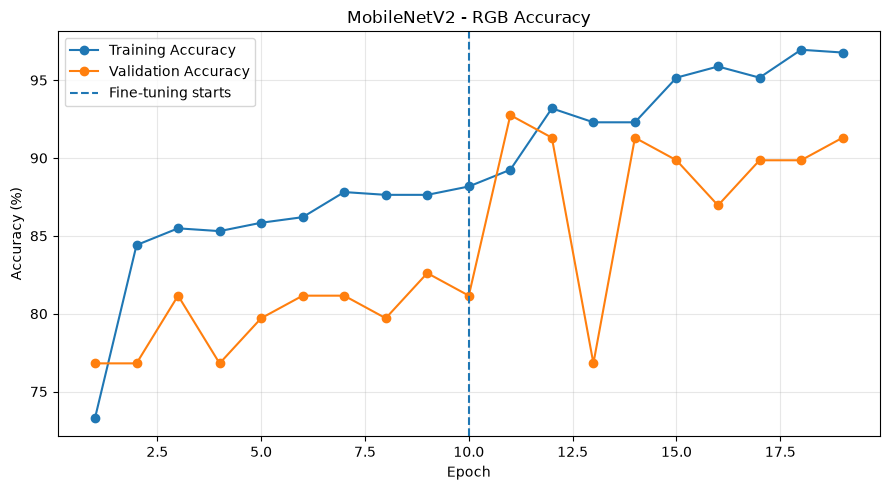

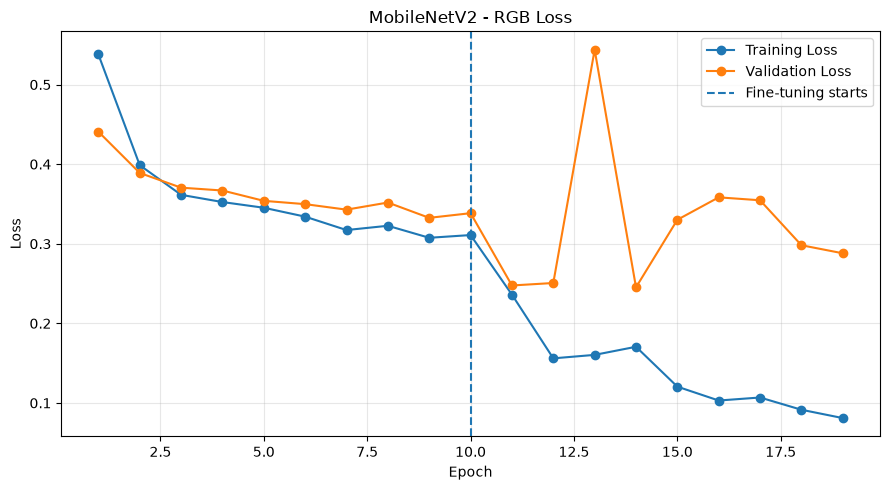

In [36]:
import matplotlib.pyplot as plt

def plot_learning_curves(history, color_space):

    epochs = history["epoch"]

    # Accuracy plot
    plt.figure(figsize=(9, 5))

    plt.plot(
        epochs,
        history["train_accuracy"] * 100,
        label="Training Accuracy",
        marker="o"
    )

    plt.plot(
        epochs,
        history["val_accuracy"] * 100,
        label="Validation Accuracy",
        marker="o"
    )

    plt.axvline(
        x=10,
        linestyle="--",
        label="Fine-tuning starts"
    )

    plt.title(f"MobileNetV2 - {color_space} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Loss plot
    plt.figure(figsize=(9, 5))

    plt.plot(
        epochs,
        history["train_loss"],
        label="Training Loss",
        marker="o"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss",
        marker="o"
    )

    plt.axvline(
        x=10,
        linestyle="--",
        label="Fine-tuning starts"
    )

    plt.title(f"MobileNetV2 - {color_space} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_learning_curves(rgb_combined_history, "RGB")


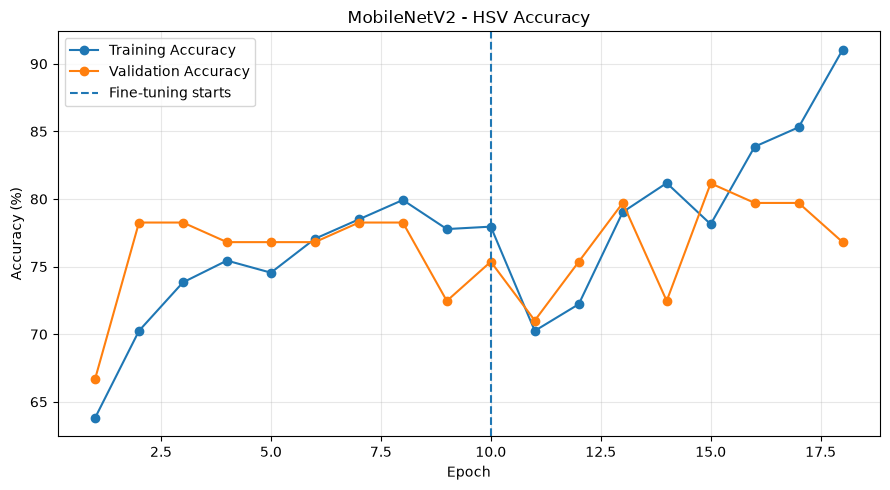

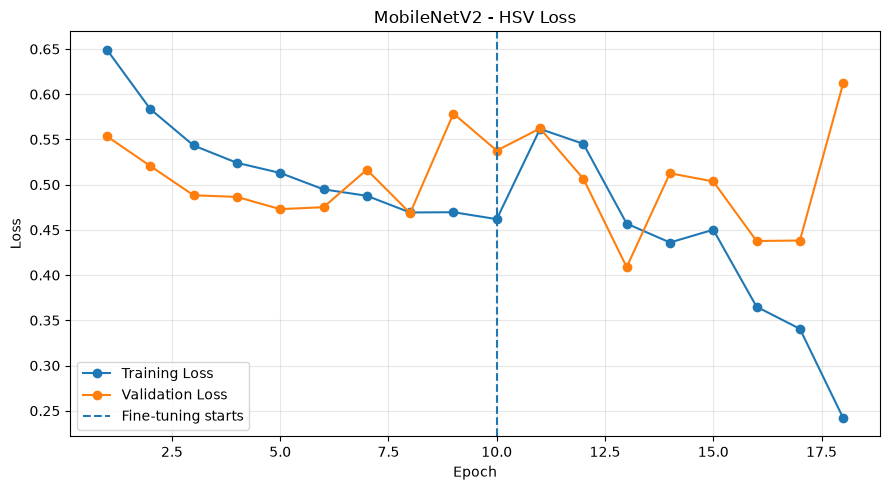

In [37]:
plot_learning_curves(hsv_combined_history, "HSV")

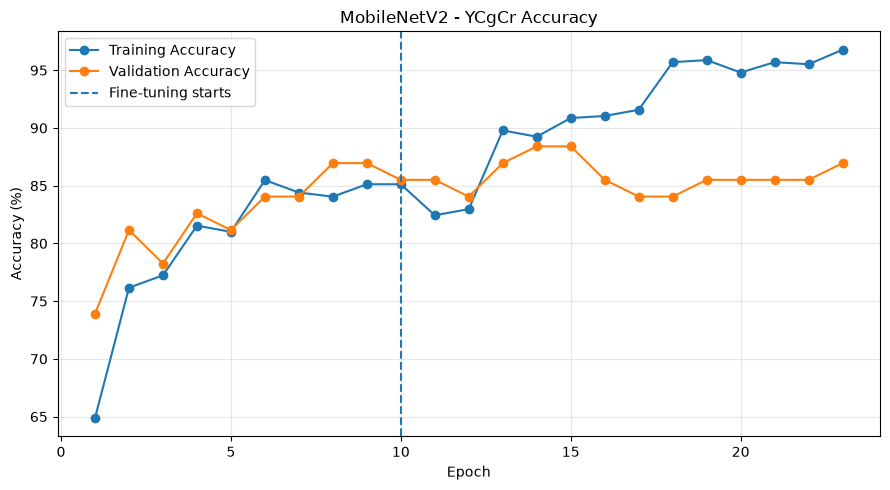

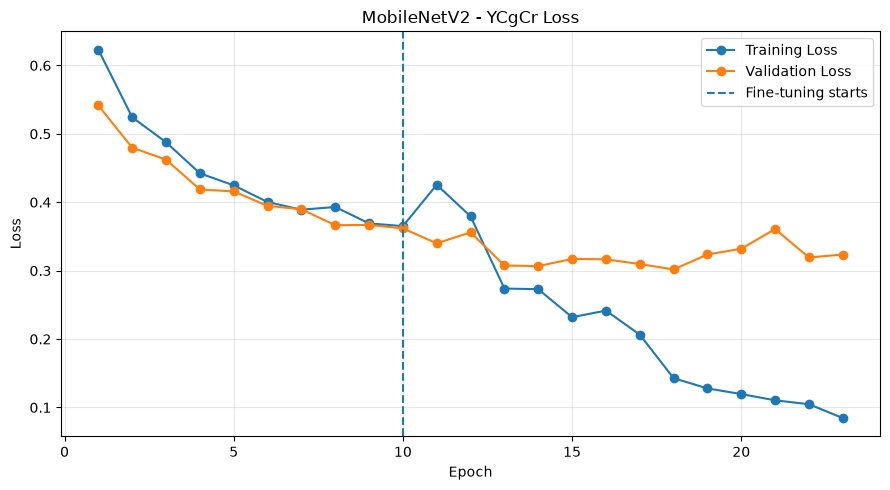

In [38]:
plot_learning_curves(ycgcr_combined_history, "YCgCr")

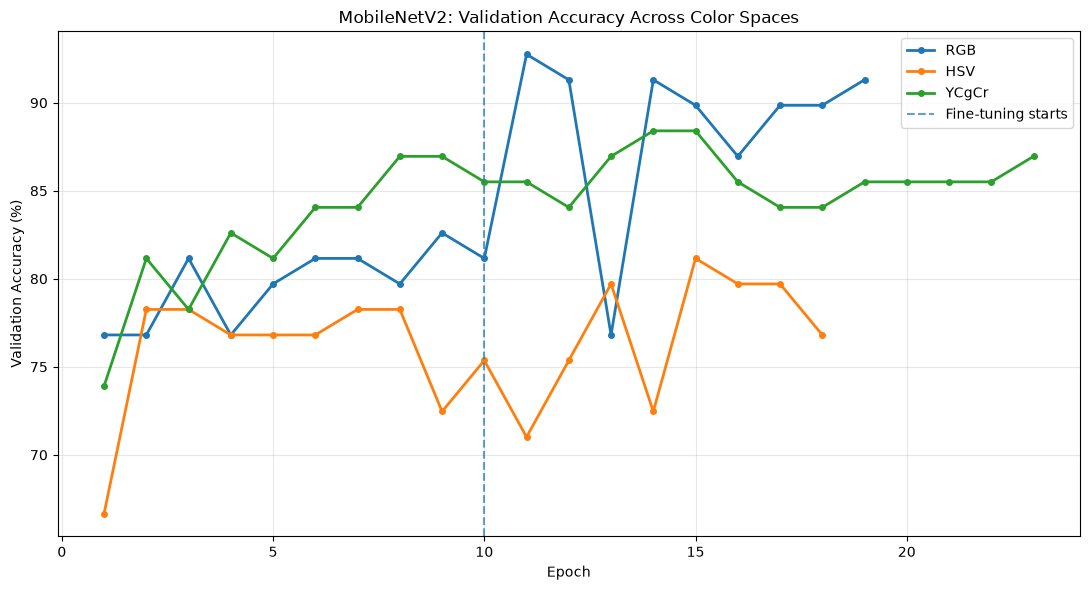

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

histories = {
    "RGB": rgb_combined_history,
    "HSV": hsv_combined_history,
    "YCgCr": ycgcr_combined_history
}

for color_space, history in histories.items():

    plt.plot(
        history["epoch"],
        history["val_accuracy"] * 100,
        marker="o",
        linewidth=2,
        markersize=4,
        label=color_space
    )

plt.axvline(
    x=10,
    linestyle="--",
    alpha=0.7,
    label="Fine-tuning starts"
)

plt.title("MobileNetV2: Validation Accuracy Across Color Spaces")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    MODEL_DIR / "mobilenetv2_validation_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
import torch

checkpoint_paths = {
    "RGB": MODEL_DIR / "mobilenetv2_RGB_phase2.pth",
    "HSV": MODEL_DIR / "mobilenetv2_HSV_phase2.pth",
    "YCgCr": MODEL_DIR / "mobilenetv2_YCgCr_phase2.pth"
}

for color_space, path in checkpoint_paths.items():

    print(f"{color_space}:")
    print("  Exists:", path.exists())
    print("  Path:", path)

RGB:
  Exists: True
  Path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_RGB_phase2.pth
HSV:
  Exists: True
  Path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_HSV_phase2.pth
YCgCr:
  Exists: True
  Path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_YCgCr_phase2.pth


In [41]:
for color_space, path in checkpoint_paths.items():

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{color_space}")
    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Number of entries:", len(checkpoint))
        print("First keys:", list(checkpoint.keys())[:8])


RGB
Checkpoint type: <class 'dict'>
Number of entries: 6
First keys: ['model_state_dict', 'color_space', 'phase', 'best_val_loss', 'history', 'class_to_idx']

HSV
Checkpoint type: <class 'dict'>
Number of entries: 6
First keys: ['model_state_dict', 'color_space', 'phase', 'best_val_loss', 'history', 'class_to_idx']

YCgCr
Checkpoint type: <class 'dict'>
Number of entries: 6
First keys: ['model_state_dict', 'color_space', 'phase', 'best_val_loss', 'history', 'class_to_idx']


In [44]:

import torch
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

test_results = {}
test_predictions = {}

for color_space, path in checkpoint_paths.items():

    print(f"\n{'='*60}")
    print(f"Evaluating MobileNetV2 - {color_space}")
    print(f"{'='*60}")

    # 1. Load checkpoint
    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=True
    )

    # 2. Verify class mapping
    test_dataset = dataloaders[color_space]["test"].dataset

    checkpoint_classes = checkpoint["class_to_idx"]
    dataset_mapping = test_dataset.class_to_idx

    assert checkpoint_classes == list(dataset_mapping.keys()), (
        f"Class ordering mismatch for {color_space}"
    )

    assert dataset_mapping == {
        class_name: index
        for index, class_name in enumerate(checkpoint_classes)
    }, f"Class index mismatch for {color_space}"

    assert checkpoint["color_space"] == color_space

    print("Class mapping verified:", dataset_mapping)

    # 3. Initialize model and load trained weights
    model = build_mobilenetv2(freeze_backbone=False)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    # 4. Prepare test evaluation
    y_true = []
    y_pred = []

    total_loss = 0.0
    total_samples = 0

    test_loader = dataloaders[color_space]["test"]

    # 5. Evaluate on untouched test set
    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            predictions = torch.argmax(outputs, dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    # 6. Calculate final metrics
    test_loss = total_loss / total_samples

    metrics = {
        "Color Space": color_space,
        "Test Samples": total_samples,
        "Test Loss": test_loss,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }

    test_results[color_space] = metrics

    # 7. Store predictions and confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    test_predictions[color_space] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "confusion_matrix": cm
    }

    # 8. Display metrics
    print("\nTest Samples:", total_samples)
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Accuracy: {metrics['Accuracy'] * 100:.2f}%")
    print(f"Macro Precision: {metrics['Macro Precision']:.4f}")
    print(f"Macro Recall: {metrics['Macro Recall']:.4f}")
    print(f"Macro F1: {metrics['Macro F1']:.4f}")
    print(f"Balanced Accuracy: {metrics['Balanced Accuracy']:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(cm)


print("\n" + "="*60)
print("ALL THREE TEST EVALUATIONS COMPLETED")
print("="*60)



Evaluating MobileNetV2 - RGB
Class mapping verified: {'Ripe': 0, 'Unripe': 1}

Test Samples: 70
Test Loss: 0.1967
Accuracy: 91.43%
Macro Precision: 0.9252
Macro Recall: 0.8925
Macro F1: 0.9049
Balanced Accuracy: 0.8925

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.95      0.81      0.88        26
      Unripe       0.90      0.98      0.93        44

    accuracy                           0.91        70
   macro avg       0.93      0.89      0.90        70
weighted avg       0.92      0.91      0.91        70

Confusion Matrix:
[[21  5]
 [ 1 43]]

Evaluating MobileNetV2 - HSV
Class mapping verified: {'Ripe': 0, 'Unripe': 1}

Test Samples: 70
Test Loss: 0.4037
Accuracy: 81.43%
Macro Precision: 0.8062
Macro Recall: 0.7893
Macro F1: 0.7959
Balanced Accuracy: 0.7893

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.78      0.69      0.73        26
      Unripe       0.83      0.89      

In [43]:
for color_space, path in checkpoint_paths.items():

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    test_dataset = dataloaders[color_space]["test"].dataset

    print(f"\n{'='*45}")
    print(color_space)
    print("Checkpoint mapping:", checkpoint["class_to_idx"])
    print("Dataset mapping:", test_dataset.class_to_idx)
    print("Checkpoint color space:", checkpoint["color_space"])
    print("Checkpoint phase:", checkpoint["phase"])


RGB
Checkpoint mapping: ['Ripe', 'Unripe']
Dataset mapping: {'Ripe': 0, 'Unripe': 1}
Checkpoint color space: RGB
Checkpoint phase: 2

HSV
Checkpoint mapping: ['Ripe', 'Unripe']
Dataset mapping: {'Ripe': 0, 'Unripe': 1}
Checkpoint color space: HSV
Checkpoint phase: 2

YCgCr
Checkpoint mapping: ['Ripe', 'Unripe']
Dataset mapping: {'Ripe': 0, 'Unripe': 1}
Checkpoint color space: YCgCr
Checkpoint phase: 2


In [45]:

# Convert final test metrics into a DataFrame
test_comparison = pd.DataFrame(
    list(test_results.values())
)

# Sort by Macro F1
test_comparison = test_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

# Save results
test_comparison_path = (
    MODEL_DIR / "mobilenetv2_final_test_comparison.csv"
)

test_comparison.to_csv(
    test_comparison_path,
    index=False
)

print("Final test comparison saved:")
print(test_comparison_path)

display(
    test_comparison.style.format({
        "Test Loss": "{:.4f}",
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Balanced Accuracy": "{:.4f}"
    })
)


Final test comparison saved:
c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_final_test_comparison.csv


,Color Space,Test Samples,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,YCgCr,70,0.2187,92.86%,0.9490,0.9038,0.9199,0.9038
1,RGB,70,0.1967,91.43%,0.9252,0.8925,0.9049,0.8925
2,HSV,70,0.4037,81.43%,0.8062,0.7893,0.7959,0.7893


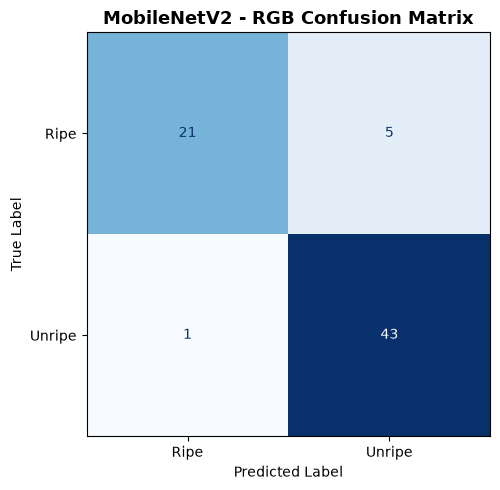

Saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_RGB_confusion_matrix.png


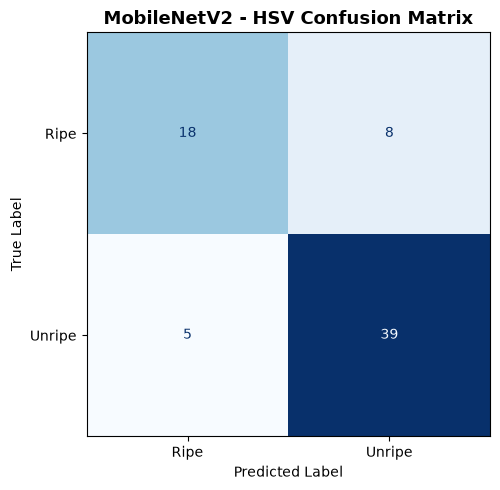

Saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_HSV_confusion_matrix.png


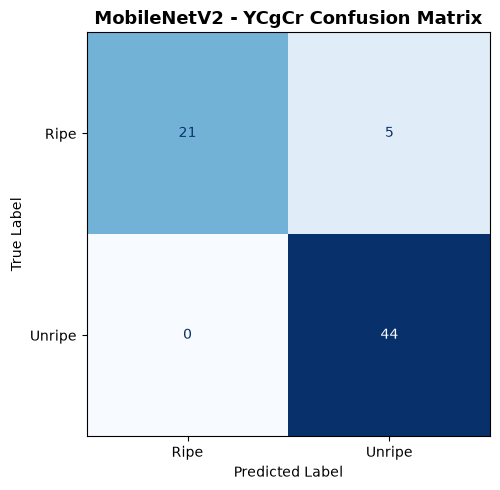

Saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\mobilenetv2_YCgCr_confusion_matrix.png


In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for color_space in ["RGB", "HSV", "YCgCr"]:

    cm = test_predictions[color_space]["confusion_matrix"]

    fig, ax = plt.subplots(figsize=(6, 5))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"MobileNetV2 - {color_space} Confusion Matrix",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    plt.tight_layout()

    save_path = MODEL_DIR / f"mobilenetv2_{color_space}_confusion_matrix.png"

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

In [48]:
from pathlib import Path
from PIL import Image
import pandas as pd

# Original dataset directory
DATASET_DIR = Path("../dataset/extracted/Dataset")

classes = {
    "Ripe": DATASET_DIR / "Ripe_Input_images",
    "Unripe": DATASET_DIR / "Un_ripe_Input_Images"
}

records = []

for class_name, folder in classes.items():
    for img_path in folder.iterdir():
        if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            try:
                with Image.open(img_path) as img:
                    records.append({
                        "class": class_name,
                        "filename": img_path.name,
                        "format": img.format,
                        "width": img.width,
                        "height": img.height,
                        "mode": img.mode,
                        "size_MB": round(img_path.stat().st_size / (1024**2), 3)
                    })
            except Exception as e:
                print(f"Error reading {img_path}: {e}")

df = pd.DataFrame(records)

print("TOTAL DATASET DETAILS")
print("=====================")
print("Total images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts())

print("\nImage formats:")
print(df["format"].value_counts())

print("\nImage dimensions:")
print(df.groupby("class")[["width", "height"]].describe())

print("\nImage size statistics (MB):")
print(df["size_MB"].describe())

print("\nImage color modes:")
print(df["mode"].value_counts())

TOTAL DATASET DETAILS
Total images: 1017

Class distribution:
class
Unripe    629
Ripe      388
Name: count, dtype: int64

Image formats:
format
JPEG    1014
MPO        3
Name: count, dtype: int64

Image dimensions:
        width                                                           \
        count         mean         std     min     25%     50%     75%   
class                                                                    
Ripe    388.0  4011.090206  443.154227  1506.0  4160.0  4160.0  4160.0   
Unripe  629.0  4031.128776  345.155436  2549.0  4160.0  4160.0  4160.0   

               height                                                   \
           max  count         mean         std     min     25%     50%   
class                                                                    
Ripe    4608.0  388.0  3202.610825  376.670200  1200.0  3120.0  3120.0   
Unripe  4160.0  629.0  3217.248013  320.534817  2242.0  3120.0  3120.0   

                        
           75%   

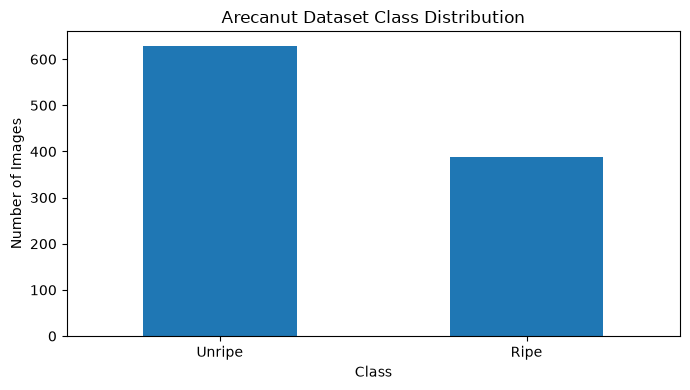

In [49]:
import matplotlib.pyplot as plt

df["class"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Arecanut Dataset Class Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [50]:
df.to_csv("dataset_details.csv", index=False)
print("Dataset details saved successfully.")

Dataset details saved successfully.


In [52]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

matches = list(
    PROJECT_DIR.rglob("final_grouped_split_manifest.csv")
)

print("Current directory:", Path.cwd())
print("Project directory:", PROJECT_DIR)

if matches:
    MANIFEST_PATH = matches[0]
    print("\nManifest found:", MANIFEST_PATH)
else:
    print("\nManifest not found. Check the audit folder.")

Current directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks
Project directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter

Manifest found: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\research-notes\audit\final_grouped_split_manifest.csv


In [53]:
import pandas as pd

df = pd.read_csv(MANIFEST_PATH)

# Original categorization
print("\n========== DATASET CATEGORIZATION ==========")
print(df["action"].value_counts())

# Class-wise categorization
print("\n========== CLASS-WISE BREAKDOWN ==========")
print(pd.crosstab(df["action"], df["class"], margins=True))

# Retained dataset
keep_df = df[df["action"] == "KEEP"].copy()

print("\n========== FINAL DATASET ==========")
print("Total retained:", len(keep_df))
print(keep_df["class"].value_counts())

# Train, validation, test
print("\n========== DATASET SPLIT ==========")
print(pd.crosstab(keep_df["split"], keep_df["class"], margins=True))

# Duplicate group verification
print("\n========== LEAKAGE CHECK ==========")
print("Unique split groups:", keep_df["split_group"].nunique())
print(
    "Groups crossing splits:",
    (keep_df.groupby("split_group")["split"].nunique() > 1).sum()
)


========== DATASET CATEGORIZATION ==========
action
KEEP    697
Name: count, dtype: int64

========== CLASS-WISE BREAKDOWN ==========
class   Ripe  Unripe  All
action                   
KEEP     255     442  697
All      255     442  697

========== FINAL DATASET ==========
Total retained: 697
class
Unripe    442
Ripe      255
Name: count, dtype: int64

========== DATASET SPLIT ==========
class       Ripe  Unripe  All
split                        
test          26      44   70
train        204     354  558
validation    25      44   69
All          255     442  697

========== LEAKAGE CHECK ==========
Unique split groups: 695
Groups crossing splits: 0


In [54]:
from pathlib import Path
import pandas as pd

# Original dataset folders
DATASET_DIR = Path("../dataset/extracted/Dataset")

# Get all original image files
original_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

original_size = sum(p.stat().st_size for p in original_files)

# Audit manifest
df = pd.read_csv(MANIFEST_PATH)

keep_df = df[df["action"] == "KEEP"]
duplicate_df = df[df["action"] == "DUPLICATE_COPY"]
quarantine_df = df[df["action"] == "QUARANTINE_LABEL_CONFLICT"]

def size_of_files(file_paths):
    return sum(Path(p).stat().st_size for p in file_paths if Path(p).exists())

# File sizes from manifest paths
duplicate_size = size_of_files(duplicate_df["path"])
keep_size = size_of_files(keep_df["path"])
quarantine_size = size_of_files(quarantine_df["path"])

print("=" * 55)
print("          COMPLETE DATASET SIZE REPORT")
print("=" * 55)

print(f"Original dataset : {len(original_files)} images | {original_size / (1024**3):.3f} GB")
print(f"Duplicate copies : {len(duplicate_df)} images | {duplicate_size / (1024**3):.3f} GB")
print(f"Quarantined      : {len(quarantine_df)} images | {quarantine_size / (1024**3):.3f} GB")
print(f"Final retained   : {len(keep_df)} images | {keep_size / (1024**3):.3f} GB")

print("=" * 55)
print("CLASS DISTRIBUTION")
print("=" * 55)

print(keep_df["class"].value_counts())

print("\nTRAIN / VALIDATION / TEST")

print(pd.crosstab(keep_df["split"], keep_df["class"], margins=True))

          COMPLETE DATASET SIZE REPORT
Original dataset : 1017 images | 3.930 GB
Duplicate copies : 0 images | 0.000 GB
Quarantined      : 0 images | 0.000 GB
Final retained   : 697 images | 2.687 GB
CLASS DISTRIBUTION
class
Unripe    442
Ripe      255
Name: count, dtype: int64

TRAIN / VALIDATION / TEST
class       Ripe  Unripe  All
split                        
test          26      44   70
train        204     354  558
validation    25      44   69
All          255     442  697


In [55]:
import pandas as pd

df = pd.read_csv(MANIFEST_PATH)

print("ACTION COLUMN VALUES:")
print(df["action"].value_counts(dropna=False).to_string())

print("\nUNIQUE ACTION LABELS:")
print(df["action"].unique())

print("\nMANIFEST TOTAL RECORDS:", len(df))

print("\nMANIFEST COLUMNS:")
print(df.columns.tolist())

ACTION COLUMN VALUES:
action
KEEP    697

UNIQUE ACTION LABELS:
<StringArray>
['KEEP']
Length: 1, dtype: str

MANIFEST TOTAL RECORDS: 697

MANIFEST COLUMNS:
['group_id', 'filename', 'class', 'path', 'group_size', 'action', 'representative', 'pixel_hash', 'split_group', 'split']


In [3]:

import pandas as pd
from pathlib import Path

# ============================================================
# MOBILENETV2 — LOAD SAVED EXPERIMENT DATA
# ============================================================

MODEL_DIR = Path.cwd().parent / "models" / "mobilenetv2"

# Load original training histories
mobilenet_histories = {}

for color_space in ["RGB", "HSV", "YCgCr"]:

    history_path = (
        MODEL_DIR / f"mobilenetv2_{color_space}_history.csv"
    )

    mobilenet_histories[color_space] = pd.read_csv(
        history_path
    )

    print(f"\n{color_space} HISTORY")
    print("=" * 45)
    print("Shape:", mobilenet_histories[color_space].shape)
    print("Columns:", list(mobilenet_histories[color_space].columns))
    display(mobilenet_histories[color_space].head(3))


# Load final test comparison
test_results = pd.read_csv(
    MODEL_DIR / "mobilenetv2_final_test_comparison.csv"
)

print("\nFINAL TEST COMPARISON")
print("=" * 60)
display(test_results)


# Load validation comparison
validation_results = pd.read_csv(
    MODEL_DIR / "mobilenetv2_validation_comparison.csv"
)

print("\nVALIDATION COMPARISON")
print("=" * 60)
display(validation_results)

print("\nAll MobileNetV2 experiment files loaded successfully.")



RGB HISTORY
Shape: (19, 9)
Columns: ['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate', 'phase']


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
0,1,0.537863,0.732975,0.671743,0.440809,0.768116,0.753131,0.001,Phase 1
1,2,0.398729,0.844086,0.825752,0.388991,0.768116,0.753131,0.001,Phase 1
2,3,0.361485,0.854839,0.840178,0.370488,0.811594,0.794313,0.001,Phase 1



HSV HISTORY
Shape: (18, 9)
Columns: ['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate', 'phase']


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
0,1,0.649190,0.637993,0.501477,0.553474,0.666667,0.497944,0.001,Phase 1
1,2,0.583597,0.702509,0.616714,0.520650,0.782609,0.770255,0.001,Phase 1
2,3,0.543336,0.738351,0.684799,0.488252,0.782609,0.766734,0.001,Phase 1



YCgCr HISTORY
Shape: (23, 9)
Columns: ['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate', 'phase']


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,phase
0,1,0.622924,0.648746,0.459815,0.541449,0.739130,0.633844,0.001,Phase 1
1,2,0.524160,0.761649,0.713374,0.479659,0.811594,0.780416,0.001,Phase 1
2,3,0.487717,0.772401,0.741473,0.462304,0.782609,0.766734,0.001,Phase 1



FINAL TEST COMPARISON


,Color Space,Test Samples,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,YCgCr,70,0.218750,0.928571,0.948980,0.903846,0.919927,0.903846
1,RGB,70,0.196745,0.914286,0.925189,0.892483,0.904891,0.892483
2,HSV,70,0.403666,0.814286,0.806198,0.789336,0.795918,0.789336



VALIDATION COMPARISON


,Color Space,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Macro F1,Total Epochs
0,RGB,14,0.245251,91.304348,0.905909,19
1,YCgCr,18,0.301672,84.057971,0.822539,23
2,HSV,13,0.408852,79.710145,0.787037,18



All MobileNetV2 experiment files loaded successfully.


MobileNetV2 data loaded and verified.
Graph output directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\graphs


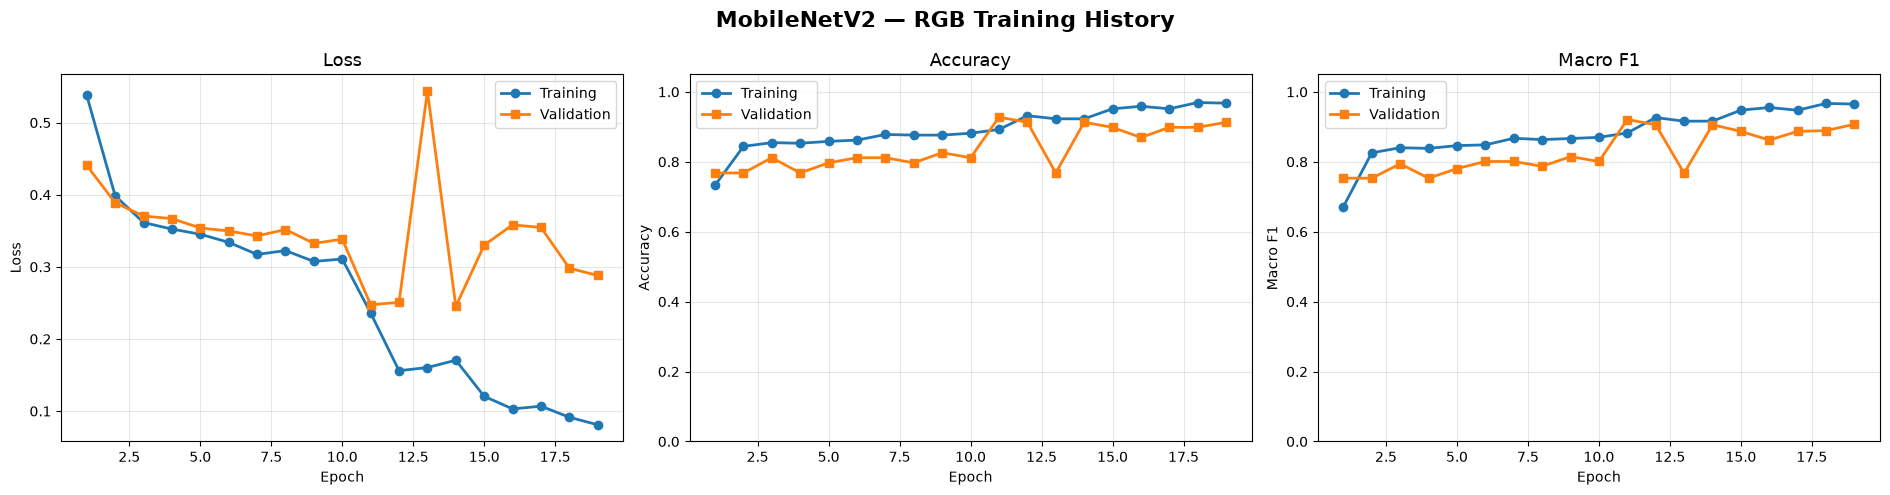

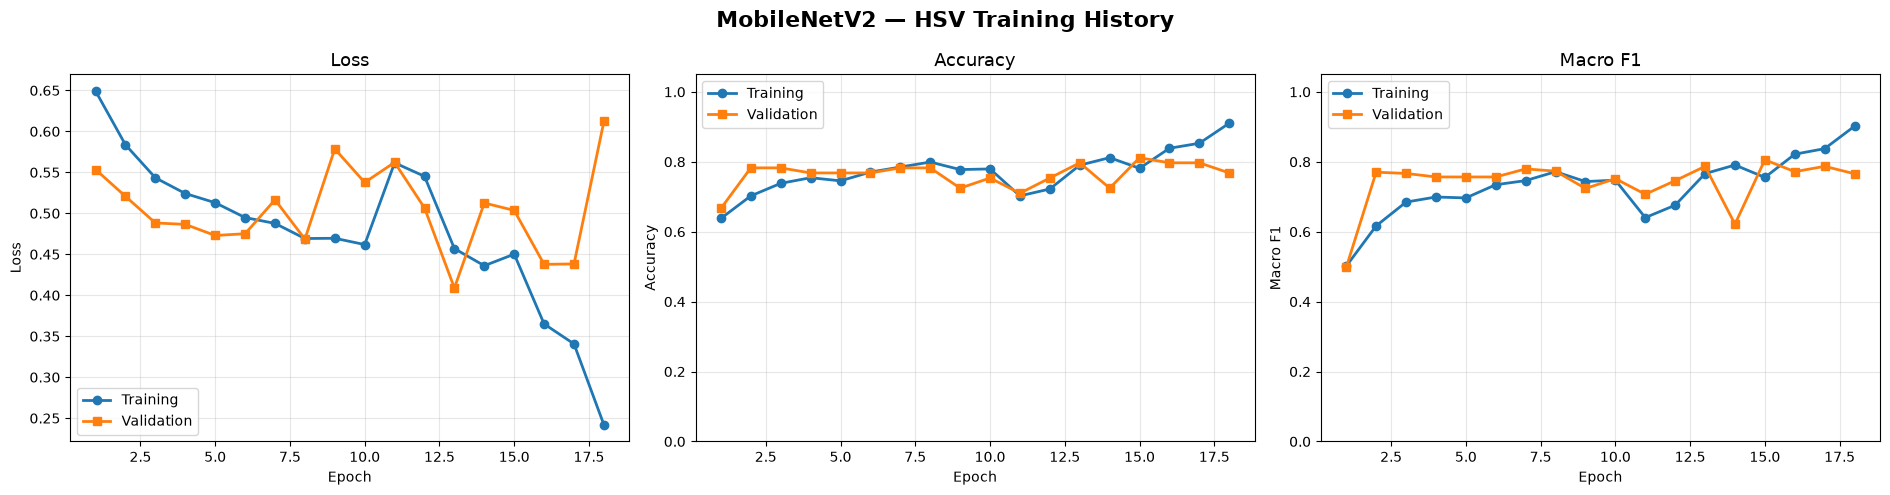

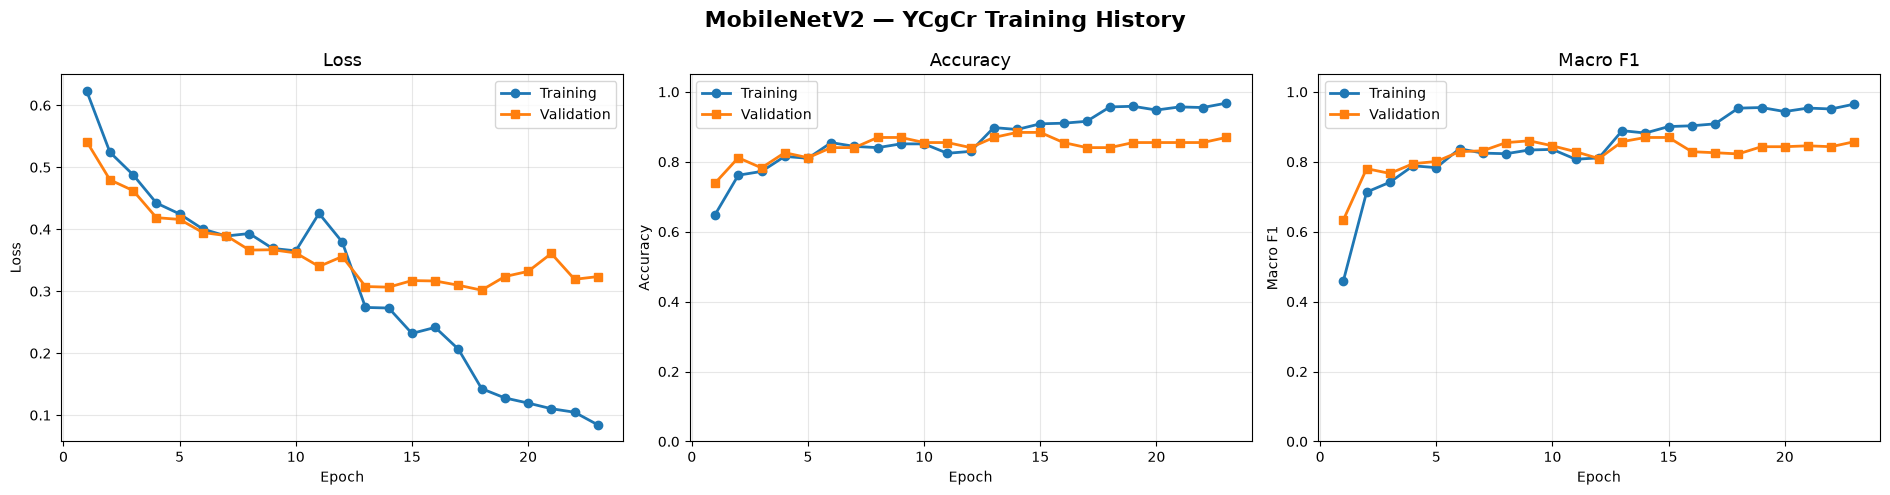

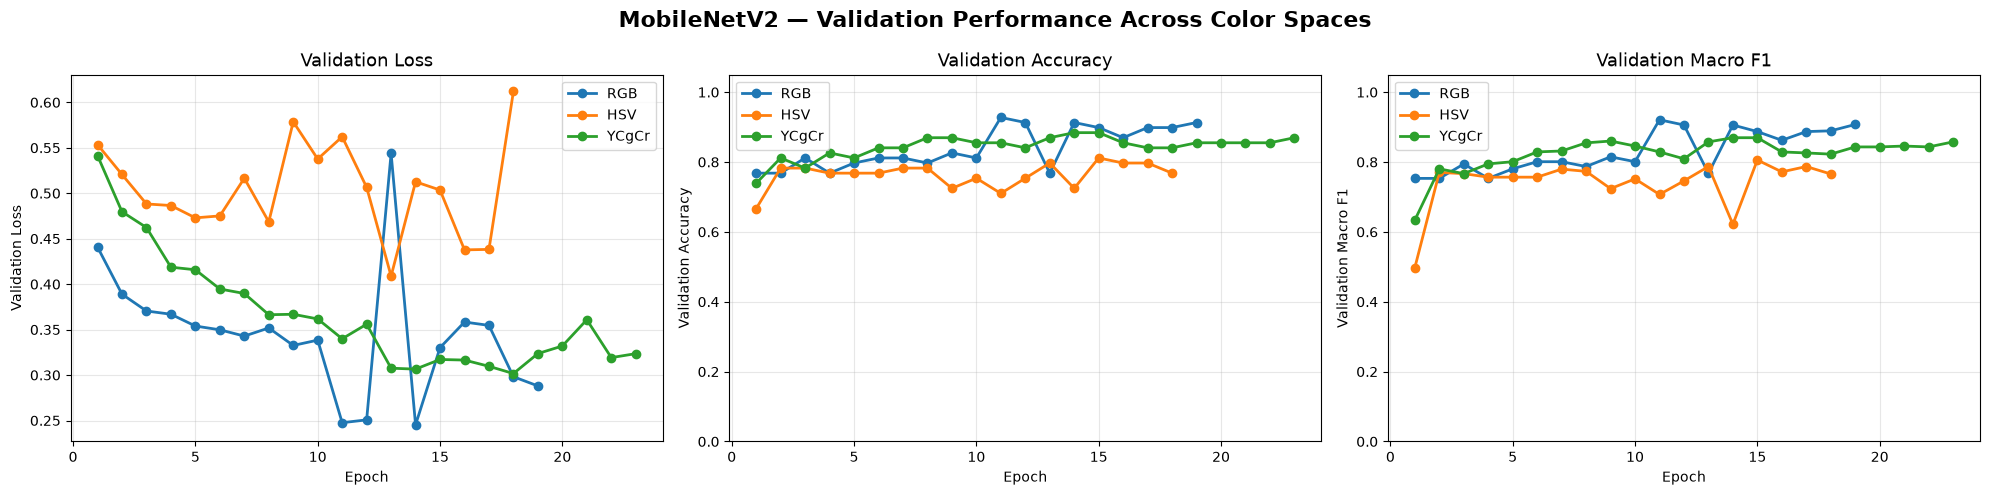

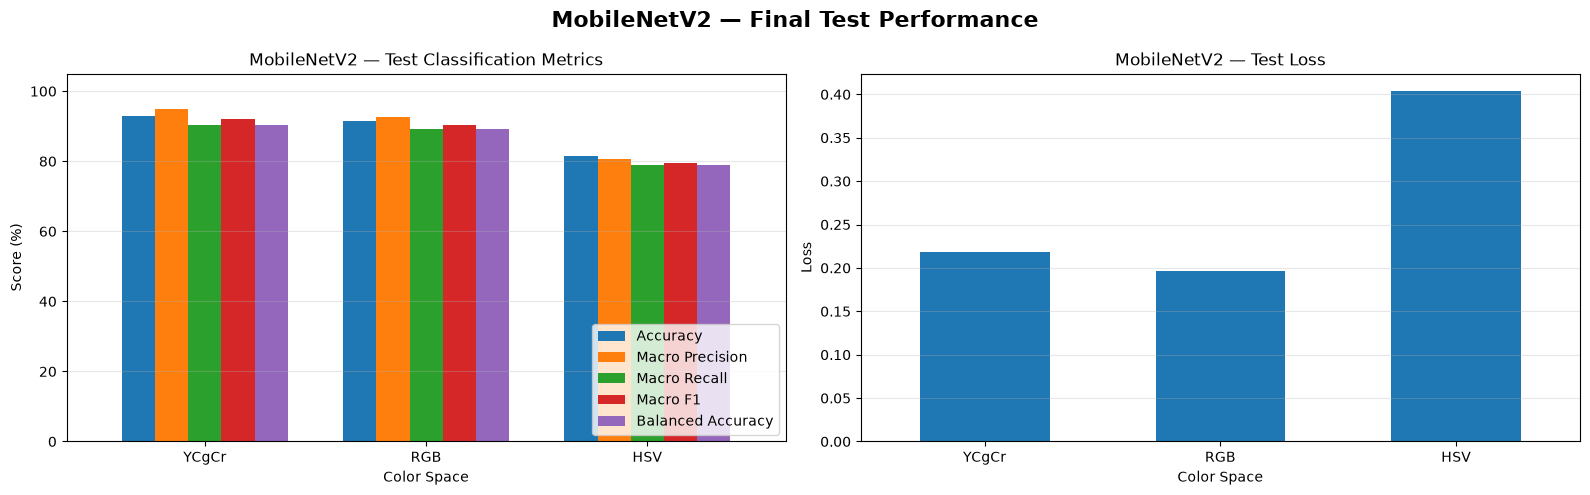

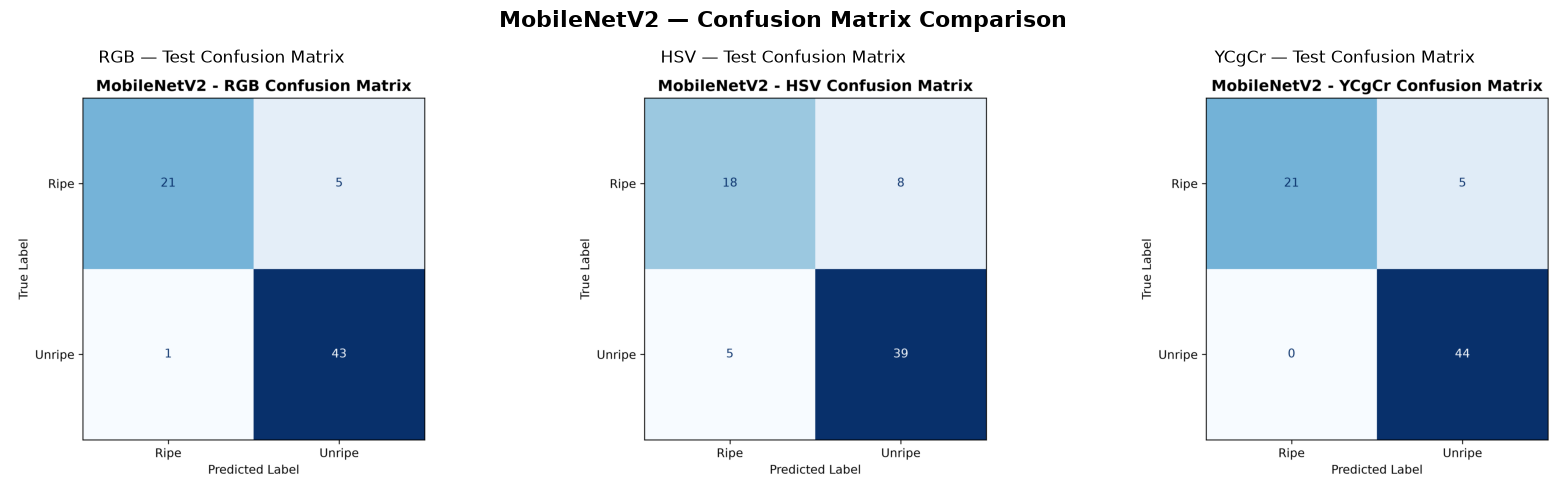


MOBILENETV2 VALIDATION COMPARISON


,Color Space,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Macro F1,Total Epochs
0,RGB,14,0.245251,91.304348,0.905909,19
1,YCgCr,18,0.301672,84.057971,0.822539,23
2,HSV,13,0.408852,79.710145,0.787037,18



MOBILENETV2 FINAL TEST RESULTS


,Color Space,Test Samples,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,YCgCr,70,0.2187,0.9286,0.9490,0.9038,0.9199,0.9038
1,RGB,70,0.1967,0.9143,0.9252,0.8925,0.9049,0.8925
2,HSV,70,0.4037,0.8143,0.8062,0.7893,0.7959,0.7893



# MobileNetV2 — Experimental Results and Conclusion

## 1. Experimental Overview

MobileNetV2 was evaluated using three input color-space
representations: RGB, HSV, and YCgCr.

The experiments used the same grouped training,
validation, and test dataset split.

## 2. Test Performance

| Color Space | Accuracy | Macro Precision | Macro Recall | Macro F1 | Test Loss |
|---|---:|---:|---:|---:|---:|
| YCgCr | 92.86% | 0.9490 | 0.9038 | 0.9199 | 0.2187 |\n| RGB | 91.43% | 0.9252 | 0.8925 | 0.9049 | 0.1967 |\n| HSV | 81.43% | 0.8062 | 0.7893 | 0.7959 | 0.4037 |\n

## 3. Key Findings

- **YCgCr** achieved the highest observed test
  accuracy of 92.86%.
- **YCgCr** achieved the highest observed macro F1
  score of 0.9199.
- **RGB** recorded the lowest test loss
  (0.1967).

These metrics describe different aspects of performance.
The highest accuracy, highest macro F1, and lowest loss
should not be treated as interchangeable.

## 4. Validation Checkpoint Results

The best validation checkpoints were selected using
validation loss. The saved validation comparison is:

Color Space  Best Epoch  Validation Loss  Validation Accuracy (%)  Validation Macro F1  Total Epochs
        RGB          14         0.245251                91.304348             0.905909            19
      YCgCr          18         0.301672                84.057971             0.822539            23
        HSV          13         0.408852                79.710145             0.787037            18

## 5. Research Interpretation

Under the current experimental configuration, YCgCr
provided the strongest observed classification performance
in terms of test accuracy and macro F1.

RGB also performed competitively and recorded the lowest
test loss.

HSV achieved lower test performance than the other two
representations in this experiment.

These findings apply to this dataset, split, preprocessing
pipeline, and training configuration. They do not establish
that one color space is universally superior.

## 6. Limitations

- The test set contains only 70 images.
- Results are based on one grouped train-validation-test split.
- A single run does not establish statistical significance.
- External field validation under different illumination,
  occlusion, and background conditions is still required.
- Confidence intervals and repeated-seed experiments would
  provide stronger evidence of performance stability.

## 7. Final Conclusion

Among the three evaluated input representations,
MobileNetV2 with YCgCr achieved the highest observed
test accuracy (92.86%) and macro F1
(0.9199).

RGB recorded the lowest test loss (0.1967).

Therefore, YCgCr is the strongest candidate based on
the observed test accuracy and macro F1, while further
independent validation and repeated experiments are needed
before drawing broader conclusions.



MOBILENETV2 VISUALIZATION PACKAGE COMPLETED
mobilenetv2_combined_validation_comparison.png
mobilenetv2_confusion_matrices.png
mobilenetv2_final_test_results.csv
mobilenetv2_HSV_training_history.png
mobilenetv2_research_conclusion.md
mobilenetv2_RGB_training_history.png
mobilenetv2_test_performance_comparison.png
mobilenetv2_YCgCr_training_history.png

All graphs and conclusion saved in:
c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\mobilenetv2\graphs


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display as show_table, Markdown

# ============================================================
# 1. PATHS AND DATA
# ============================================================

PROJECT_DIR = Path.cwd().parent
MODEL_DIR = PROJECT_DIR / "models" / "mobilenetv2"
GRAPH_DIR = MODEL_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

COLOR_SPACES = ["RGB", "HSV", "YCgCr"]

histories = {
    cs: pd.read_csv(MODEL_DIR / f"mobilenetv2_{cs}_history.csv")
    for cs in COLOR_SPACES
}

test_results = pd.read_csv(
    MODEL_DIR / "mobilenetv2_final_test_comparison.csv"
)

validation_results = pd.read_csv(
    MODEL_DIR / "mobilenetv2_validation_comparison.csv"
)

# Validate expected columns
required_history_columns = [
    "epoch", "train_loss", "train_accuracy", "train_macro_f1",
    "val_loss", "val_accuracy", "val_macro_f1", "phase"
]

for cs, df in histories.items():
    missing = set(required_history_columns) - set(df.columns)
    if missing:
        raise ValueError(f"{cs} history is missing columns: {missing}")

print("MobileNetV2 data loaded and verified.")
print("Graph output directory:", GRAPH_DIR)


# ============================================================
# 2. INDIVIDUAL TRAINING HISTORY GRAPHS
# ============================================================

metrics = [
    ("train_loss", "val_loss", "Loss"),
    ("train_accuracy", "val_accuracy", "Accuracy"),
    ("train_macro_f1", "val_macro_f1", "Macro F1")
]

for cs, df in histories.items():

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    epochs = df["epoch"]

    for ax, (train_col, val_col, title) in zip(axes, metrics):

        ax.plot(
            epochs, df[train_col],
            marker="o", linewidth=2,
            label="Training"
        )

        ax.plot(
            epochs, df[val_col],
            marker="s", linewidth=2,
            label="Validation"
        )

        ax.set_title(title, fontsize=13)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)
        ax.legend()

        if title != "Loss":
            ax.set_ylim(0, 1.05)

    fig.suptitle(
        f"MobileNetV2 — {cs} Training History",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    fig.savefig(
        GRAPH_DIR / f"mobilenetv2_{cs}_training_history.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 3. COMBINED VALIDATION CURVES
# ============================================================

combined_metrics = [
    ("val_loss", "Validation Loss"),
    ("val_accuracy", "Validation Accuracy"),
    ("val_macro_f1", "Validation Macro F1")
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (column, title) in zip(axes, combined_metrics):

    for cs, df in histories.items():

        ax.plot(
            df["epoch"],
            df[column],
            marker="o",
            linewidth=2,
            label=cs
        )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

    if column != "val_loss":
        ax.set_ylim(0, 1.05)

fig.suptitle(
    "MobileNetV2 — Validation Performance Across Color Spaces",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "mobilenetv2_combined_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 4. TEST PERFORMANCE COMPARISON
# ============================================================

# Standardize the color-space column for plotting
results = test_results.copy()

if "Color Space" not in results.columns:
    raise ValueError("Expected 'Color Space' column in test results.")

results = results.set_index("Color Space")

test_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]

missing = set(test_metrics + ["Test Loss"]) - set(results.columns)

if missing:
    raise ValueError(f"Test comparison CSV is missing: {missing}")

# Convert metric values to percentage for plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

results[test_metrics].mul(100).plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].set_title("MobileNetV2 — Test Classification Metrics")
axes[0].set_ylabel("Score (%)")
axes[0].set_xlabel("Color Space")
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right")

results["Test Loss"].plot(
    kind="bar",
    ax=axes[1],
    width=0.55
)

axes[1].set_title("MobileNetV2 — Test Loss")
axes[1].set_ylabel("Loss")
axes[1].set_xlabel("Color Space")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "MobileNetV2 — Final Test Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "mobilenetv2_test_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 5. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, cs in zip(axes, COLOR_SPACES):

    cm_path = MODEL_DIR / f"mobilenetv2_{cs}_confusion_matrix.png"

    if cm_path.exists():
        img = Image.open(cm_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"{cs} — Test Confusion Matrix")
        ax.axis("off")
    else:
        ax.text(
            0.5, 0.5,
            f"Confusion matrix not found:\n{cs}",
            ha="center", va="center"
        )
        ax.axis("off")

fig.suptitle(
    "MobileNetV2 — Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "mobilenetv2_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 6. VALIDATION CHECKPOINT COMPARISON
# ============================================================

print("\nMOBILENETV2 VALIDATION COMPARISON")
print("=" * 65)

show_table(validation_results)


# ============================================================
# 7. FINAL TEST RESULTS TABLE
# ============================================================

print("\nMOBILENETV2 FINAL TEST RESULTS")
print("=" * 65)

show_table(test_results.round(4))

test_results.to_csv(
    GRAPH_DIR / "mobilenetv2_final_test_results.csv",
    index=False
)


# ============================================================
# 8. AUTOMATIC RESEARCH CONCLUSION
# ============================================================

# Read actual results from the saved CSV
accuracy_col = "Accuracy"
f1_col = "Macro F1"
loss_col = "Test Loss"

best_accuracy_row = results[accuracy_col].idxmax()
best_f1_row = results[f1_col].idxmax()
lowest_loss_row = results[loss_col].idxmin()

best_accuracy = results.loc[best_accuracy_row, accuracy_col]
best_f1 = results.loc[best_f1_row, f1_col]
lowest_loss = results.loc[lowest_loss_row, loss_col]

best_accuracy_pct = best_accuracy * 100

total_test_samples = (
    int(results["Test Samples"].iloc[0])
    if "Test Samples" in results.columns
    else None
)

validation_table = validation_results.copy()

conclusion = f"""
# MobileNetV2 — Experimental Results and Conclusion

## 1. Experimental Overview

MobileNetV2 was evaluated using three input color-space
representations: RGB, HSV, and YCgCr.

The experiments used the same grouped training,
validation, and test dataset split.

## 2. Test Performance

| Color Space | Accuracy | Macro Precision | Macro Recall | Macro F1 | Test Loss |
|---|---:|---:|---:|---:|---:|
"""

for cs in results.index:
    row = results.loc[cs]
    conclusion += (
        f"| {cs} "
        f"| {row[accuracy_col]*100:.2f}% "
        f"| {row['Macro Precision']:.4f} "
        f"| {row['Macro Recall']:.4f} "
        f"| {row[f1_col]:.4f} "
        f"| {row[loss_col]:.4f} |\\n"
    )

conclusion += f"""

## 3. Key Findings

- **{best_accuracy_row}** achieved the highest observed test
  accuracy of {best_accuracy_pct:.2f}%.
- **{best_f1_row}** achieved the highest observed macro F1
  score of {best_f1:.4f}.
- **{lowest_loss_row}** recorded the lowest test loss
  ({lowest_loss:.4f}).

These metrics describe different aspects of performance.
The highest accuracy, highest macro F1, and lowest loss
should not be treated as interchangeable.

## 4. Validation Checkpoint Results

The best validation checkpoints were selected using
validation loss. The saved validation comparison is:

{validation_table.to_string(index=False)}

## 5. Research Interpretation

Under the current experimental configuration, YCgCr
provided the strongest observed classification performance
in terms of test accuracy and macro F1.

RGB also performed competitively and recorded the lowest
test loss.

HSV achieved lower test performance than the other two
representations in this experiment.

These findings apply to this dataset, split, preprocessing
pipeline, and training configuration. They do not establish
that one color space is universally superior.

## 6. Limitations

- The test set contains only 70 images.
- Results are based on one grouped train-validation-test split.
- A single run does not establish statistical significance.
- External field validation under different illumination,
  occlusion, and background conditions is still required.
- Confidence intervals and repeated-seed experiments would
  provide stronger evidence of performance stability.

## 7. Final Conclusion

Among the three evaluated input representations,
MobileNetV2 with YCgCr achieved the highest observed
test accuracy ({best_accuracy_pct:.2f}%) and macro F1
({best_f1:.4f}).

RGB recorded the lowest test loss ({lowest_loss:.4f}).

Therefore, YCgCr is the strongest candidate based on
the observed test accuracy and macro F1, while further
independent validation and repeated experiments are needed
before drawing broader conclusions.
"""

show_table(Markdown(conclusion))

conclusion_path = GRAPH_DIR / "mobilenetv2_research_conclusion.md"

conclusion_path.write_text(
    conclusion,
    encoding="utf-8"
)


# ============================================================
# 9. EXPORT SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("MOBILENETV2 VISUALIZATION PACKAGE COMPLETED")
print("=" * 65)

for file in sorted(GRAPH_DIR.iterdir()):
    print(file.name)

print("\nAll graphs and conclusion saved in:")
print(GRAPH_DIR)
